In [17]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [18]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

from tensorflow.keras.layers import (
    Dense,
    Dropout,
    BatchNormalization,
    Activation,
    Input,
    Concatenate
)

from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

np.random.seed(42)
tf.random.set_seed(42)

In [19]:
!pip install seaborn tensorflow scikit-learn xgboost shap -q

ANALYSIS_DIR = "/content/drive/MyDrive/Sourcedata/Analysis"

IMG_DIR = os.path.join(ANALYSIS_DIR, "Images")
CSV_DIR = os.path.join(ANALYSIS_DIR, "CSV")
SHAP_DIR = os.path.join(ANALYSIS_DIR, "SHAP")

os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(CSV_DIR, exist_ok=True)
os.makedirs(SHAP_DIR, exist_ok=True)

In [20]:
BASE_DIR = "/content/drive/MyDrive/Sourcedata/extracted_data"

META_COLS = [
    "file_name","phase","window_id","sample_rate",
    "split_mode","usable_duration_sec",
    "window_start_in_phase","window_end_in_phase",
    "window_start_global","window_end_global"
]

def load_modality_df(path):

    df = pd.read_csv(path)

    y = df["phase"].copy()

    X = df.drop(
        columns=[c for c in META_COLS if c in df.columns],
        errors="ignore"
    )

    X = X.select_dtypes(include=np.number)
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.fillna(X.median())

    return X, y, df

files = {
    "EEG": Path(BASE_DIR) / "EEG_features.csv",
    "ECG": Path(BASE_DIR) / "ECG_features.csv",
    "EMG": Path(BASE_DIR) / "EMG_features.csv",
    "Fusion" : Path(BASE_DIR) / "Fusion_features.csv"
}

data = {
    m: load_modality_df(p)
    for m, p in files.items()
}

_, y_eeg, _ = data["EEG"]
le = LabelEncoder()
y = le.fit_transform(y_eeg.values)

classes = le.classes_

X_eeg = data["EEG"][0].to_numpy(dtype=np.float32)
X_ecg = data["ECG"][0].to_numpy(dtype=np.float32)
X_emg = data["EMG"][0].to_numpy(dtype=np.float32)
X_fusion = data["Fusion"][0].to_numpy(dtype=np.float32)

n = min(len(X_eeg), len(X_ecg), len(X_emg))

X_eeg = X_eeg[:n]
X_ecg = X_ecg[:n]
X_emg = X_emg[:n]
y = y[:n]

In [21]:
# ============================================================
# DATA VALIDATION
# ============================================================

print("========== DATASET SUMMARY ==========")

print(f"EEG Shape : {X_eeg.shape}")
print(f"ECG Shape : {X_ecg.shape}")
print(f"EMG Shape : {X_emg.shape}")
print(f"Fusion Shape : {X_fusion.shape}")
print(f"Labels    : {y.shape}")

print("\n========== CLASS DISTRIBUTION ==========")

unique, counts = np.unique(y, return_counts=True)

for cls, cnt in zip(classes, counts):
    print(f"{cls} : {cnt}")

print("\n========== MISSING VALUES ==========")

print("EEG Missing :", np.isnan(X_eeg).sum())
print("ECG Missing :", np.isnan(X_ecg).sum())
print("EMG Missing :", np.isnan(X_emg).sum())
print("Fusion Missing :", np.isnan(X_fusion).sum())

print("\n========== DUPLICATE ANALYSIS ==========")

combined_df = pd.DataFrame(
    np.concatenate([X_eeg, X_ecg, X_emg], axis=1)
)

print("Combined duplicates:",
      combined_df.duplicated().sum())

print("\n========== FEATURE DIMENSIONS ==========")

print(f"EEG Features : {X_eeg.shape[1]}")
print(f"ECG Features : {X_ecg.shape[1]}")
print(f"EMG Features : {X_emg.shape[1]}")
print(f"Fusion Features : {X_fusion.shape[1]}")

========== DATASET SUMMARY ==========
EEG Shape : (18681, 160)
ECG Shape : (18681, 16)
EMG Shape : (18681, 19)
Fusion Shape : (18681, 195)
Labels    : (18681,)

========== CLASS DISTRIBUTION ==========
MAR : 11201
POST : 3734
PRE : 3746

========== MISSING VALUES ==========
EEG Missing : 0
ECG Missing : 0
EMG Missing : 0
Fusion Missing : 0

========== DUPLICATE ANALYSIS ==========
Combined duplicates: 0

========== FEATURE DIMENSIONS ==========
EEG Features : 160
ECG Features : 16
EMG Features : 19
Fusion Features : 195


In [22]:
# ============================================================
# Deep Multimodal MLP Fusion Network
# ============================================================

def modality_branch(inp, name_prefix):

    x = Dense(
        64,
        name=f"{name_prefix}_dense1"
    )(inp)

    x = BatchNormalization(
        name=f"{name_prefix}_bn1"
    )(x)

    x = Activation(
        "relu",
        name=f"{name_prefix}_relu1"
    )(x)

    x = Dropout(
        0.30,
        name=f"{name_prefix}_drop1"
    )(x)

    x = Dense(
        32,
        name=f"{name_prefix}_dense2"
    )(x)

    x = BatchNormalization(
        name=f"{name_prefix}_bn2"
    )(x)

    x = Activation(
        "relu",
        name=f"{name_prefix}_relu2"
    )(x)

    x = Dropout(
        0.30,
        name=f"{name_prefix}_drop2"
    )(x)

    return x


def build_obj2_model(
    dim_eeg,
    dim_ecg,
    dim_emg,
    n_classes,
    lr=1e-3
):

    eeg_in = Input(shape=(dim_eeg,), name="EEG_Input")
    ecg_in = Input(shape=(dim_ecg,), name="ECG_Input")
    emg_in = Input(shape=(dim_emg,), name="EMG_Input")

    eeg_branch = modality_branch(eeg_in, "EEG")
    ecg_branch = modality_branch(ecg_in, "ECG")
    emg_branch = modality_branch(emg_in, "EMG")

    fusion = Concatenate(name="Multimodal_Fusion")(
        [eeg_branch, ecg_branch, emg_branch]
    )

    x = Dense(32, name="Fusion_Dense1")(fusion)
    x = BatchNormalization(name="Fusion_BN1")(x)
    x = Activation("relu", name="Fusion_ReLU1")(x)
    x = Dropout(0.30, name="Fusion_Drop1")(x)

    x = Dense(16, name="Fusion_Dense2")(x)
    x = BatchNormalization(name="Fusion_BN2")(x)
    x = Activation("relu", name="Fusion_ReLU2")(x)
    x = Dropout(0.20, name="Fusion_Drop2")(x)

    out = Dense(
        n_classes,
        activation="softmax",
        name="Output_Layer"
    )(x)

    model = Model(
        inputs=[eeg_in, ecg_in, emg_in],
        outputs=out,
        name="Objective2_Multimodal_MLP"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=lr
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [23]:
model = build_obj2_model(
    X_eeg.shape[1],
    X_ecg.shape[1],
    X_emg.shape[1],
    len(classes)
)

model.summary()

print("\n========== MODEL INFORMATION ==========")

print("Architecture Type : Deep Multimodal MLP Fusion Network")

print("Input Modalities  : EEG, ECG, EMG")

print("Embedding Size    : 32 per modality")

print("Fusion Type       : Feature-level concatenation")

print("Classifier Type   : Fully connected MLP")

print("Output Classes    :", list(classes))

Model: "Objective2_Multimodal_MLP"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ EEG_Input           │ (None, 160)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ECG_Input           │ (None, 16)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EMG_Input           │ (None, 19)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EEG_dense1 (Dense)  │ (None, 64)        │     10,304 │ EEG_Input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ECG_dense1 (Dense)  │ (None, 64)        │      1,088 │ ECG_Input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EMG_dense1 (Dense)  │ (None, 64)        │      1,280 │ EMG_Input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EEG_bn1             │ (None, 64)        │        256 │ EEG_dense1[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ECG_bn1             │ (None, 64)        │        256 │ ECG_dense1[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EMG_bn1             │ (None, 64)        │        256 │ EMG_dense1[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EEG_relu1           │ (None, 64)        │          0 │ EEG_bn1[0][0]     │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ECG_relu1           │ (None, 64)        │          0 │ ECG_bn1[0][0]     │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EMG_relu1           │ (None, 64)        │          0 │ EMG_bn1[0][0]     │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EEG_drop1 (Dropout) │ (None, 64)        │          0 │ EEG_relu1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ECG_drop1 (Dropout) │ (None, 64)        │          0 │ ECG_relu1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EMG_drop1 (Dropout) │ (None, 64)        │          0 │ EMG_relu1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EEG_dense2 (Dense)  │ (None, 32)        │      2,080 │ EEG_drop1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ECG_dense2 (Dense)  │ (None, 32)        │      2,080 │ ECG_drop1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EMG_dense2 (Dense)  │ (None, 32)        │      2,080 │ EMG_drop1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EEG_bn2             │ (None, 32)        │        128 │ EEG_dense2[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ECG_bn2             │ (None, 32)        │        128 │ ECG_dense2[0][0]

 Total params: 23,939 (93.51 KB)

 Trainable params: 23,267 (90.89 KB)

 Non-trainable params: 672 (2.62 KB)


========== MODEL INFORMATION ==========
Architecture Type : Deep Multimodal MLP Fusion Network
Input Modalities  : EEG, ECG, EMG
Embedding Size    : 32 per modality
Fusion Type       : Feature-level concatenation
Classifier Type   : Fully connected MLP
Output Classes    : ['MAR', 'POST', 'PRE']



================ FOLD 1 ================

Epoch 1/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 48s 287ms/step - accuracy: 0.2664 - loss: 1.2502 - val_accuracy: 0.4456 - val_loss: 1.0764 - learning_rate: 0.0010
Epoch 2/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3253 - loss: 1.1256 - val_accuracy: 0.4554 - val_loss: 1.0587 - learning_rate: 0.0010
Epoch 3/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.3603 - loss: 1.0910 - val_accuracy: 0.4670 - val_loss: 1.0376 - learning_rate: 0.0010
Epoch 4/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.3858 - loss: 1.0630 - val_accuracy: 0.4777 - val_loss: 1.0191 - learning_rate: 0.0010
Epoch 5/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4021 - loss: 1.0337 - val_accuracy: 0.4732 - val_loss: 1.0037 - learning_rate: 0.0010
Epoch 6/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4100 - loss: 1.0122 - val_accuracy: 0.5165 - val_loss: 0.9725 - learning_rate: 0.0010
Epoch 7/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/st

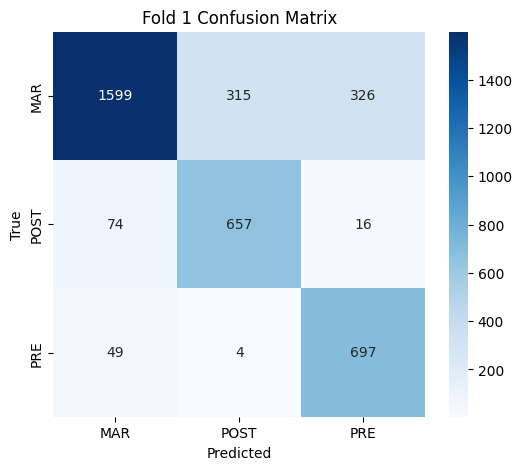


================ FOLD 2 ================

Epoch 1/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 25s 232ms/step - accuracy: 0.3502 - loss: 1.2308 - val_accuracy: 0.3292 - val_loss: 1.0855 - learning_rate: 0.0010
Epoch 2/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3565 - loss: 1.1267 - val_accuracy: 0.3747 - val_loss: 1.0668 - learning_rate: 0.0010
Epoch 3/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3614 - loss: 1.0892 - val_accuracy: 0.3800 - val_loss: 1.0488 - learning_rate: 0.0010
Epoch 4/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3609 - loss: 1.0641 - val_accuracy: 0.3961 - val_loss: 1.0326 - learning_rate: 0.0010
Epoch 5/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3742 - loss: 1.0431 - val_accuracy: 0.4090 - val_loss: 1.0211 - learning_rate: 0.0010
Epoch 6/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3894 - loss: 1.0185 - val_accuracy: 0.4376 - val_loss: 0.9910 - learning_rate: 0.0010
Epoch 7/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/s

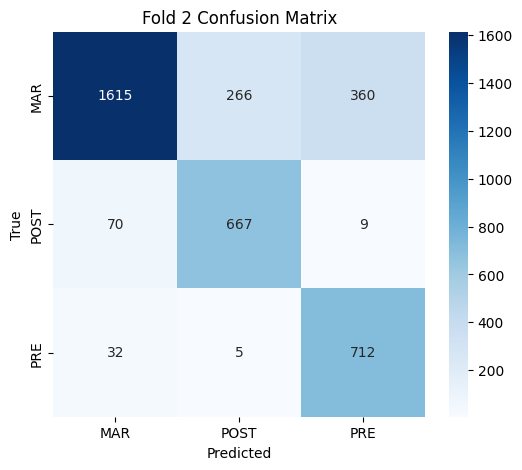


================ FOLD 3 ================

Epoch 1/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 174ms/step - accuracy: 0.3718 - loss: 1.2478 - val_accuracy: 0.4523 - val_loss: 1.0524 - learning_rate: 0.0010
Epoch 2/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.3656 - loss: 1.1390 - val_accuracy: 0.4425 - val_loss: 1.0422 - learning_rate: 0.0010
Epoch 3/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.3738 - loss: 1.1037 - val_accuracy: 0.5268 - val_loss: 1.0107 - learning_rate: 0.0010
Epoch 4/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.3877 - loss: 1.0780 - val_accuracy: 0.5098 - val_loss: 1.0026 - learning_rate: 0.0010
Epoch 5/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.4022 - loss: 1.0573 - val_accuracy: 0.5112 - val_loss: 0.9851 - learning_rate: 0.0010
Epoch 6/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.4118 - loss: 1.0302 - val_accuracy: 0.5036 - val_loss: 0.9708 - learning_rate: 0.0010
Epoch 7/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11

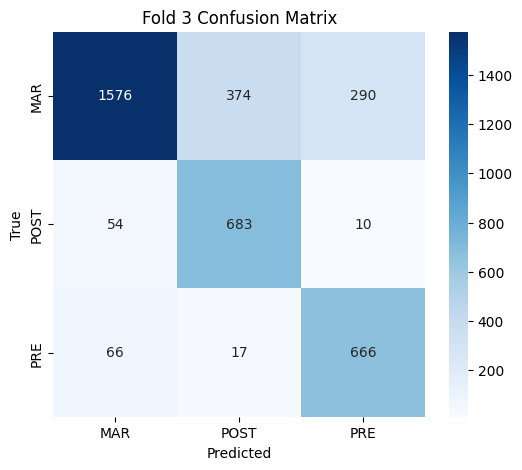


================ FOLD 4 ================

Epoch 1/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 191ms/step - accuracy: 0.3034 - loss: 1.2032 - val_accuracy: 0.4175 - val_loss: 1.0795 - learning_rate: 0.0010
Epoch 2/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.3679 - loss: 1.1185 - val_accuracy: 0.4434 - val_loss: 1.0673 - learning_rate: 0.0010
Epoch 3/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3873 - loss: 1.0950 - val_accuracy: 0.4706 - val_loss: 1.0416 - learning_rate: 0.0010
Epoch 4/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3974 - loss: 1.0634 - val_accuracy: 0.4808 - val_loss: 1.0187 - learning_rate: 0.0010
Epoch 5/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.4149 - loss: 1.0426 - val_accuracy: 0.5022 - val_loss: 0.9968 - learning_rate: 0.0010
Epoch 6/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.4243 - loss: 1.0192 - val_accuracy: 0.5013 - val_loss: 0.9841 - learning_rate: 0.0010
Epoch 7/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10

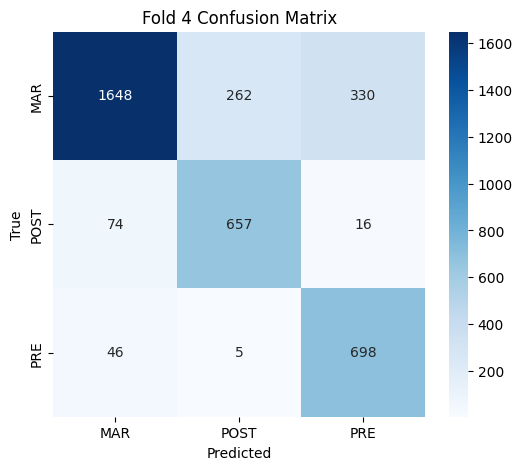


================ FOLD 5 ================

Epoch 1/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 190ms/step - accuracy: 0.3372 - loss: 1.2119 - val_accuracy: 0.4175 - val_loss: 1.0802 - learning_rate: 0.0010
Epoch 2/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3727 - loss: 1.1352 - val_accuracy: 0.4946 - val_loss: 1.0432 - learning_rate: 0.0010
Epoch 3/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3842 - loss: 1.0894 - val_accuracy: 0.5196 - val_loss: 1.0259 - learning_rate: 0.0010
Epoch 4/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4002 - loss: 1.0593 - val_accuracy: 0.5227 - val_loss: 1.0074 - learning_rate: 0.0010
Epoch 5/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4293 - loss: 1.0254 - val_accuracy: 0.5491 - val_loss: 0.9784 - learning_rate: 0.0010
Epoch 6/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4500 - loss: 0.9913 - val_accuracy: 0.5674 - val_loss: 0.9425 - learning_rate: 0.0010
Epoch 7/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/st

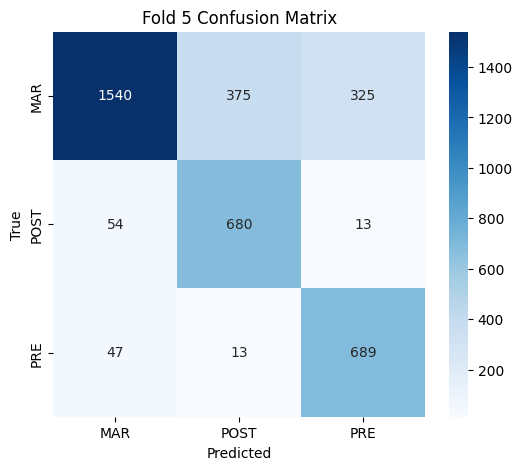


        OBJECTIVE 2 FINAL RESULTS

Mean Accuracy           : 0.7914
Mean Precision          : 0.7597
Mean Recall             : 0.8440
Mean Macro F1 Score     : 0.7846
Mean Balanced Accuracy  : 0.8440


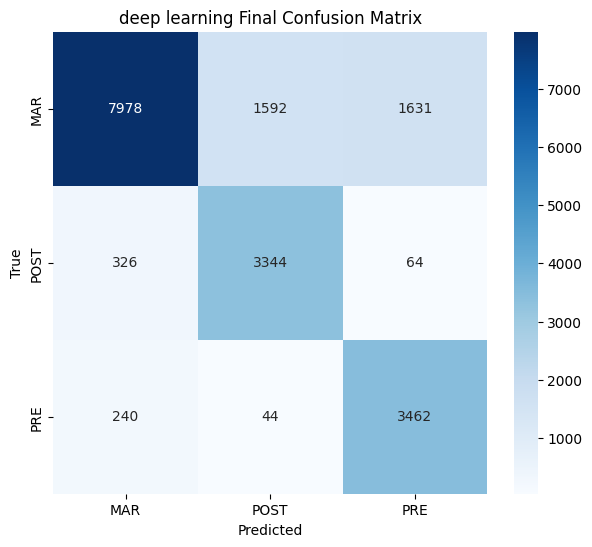

In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

# =========================================================
# CROSS VALIDATION SETUP
# =========================================================

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_acc = []
fold_prec = []
fold_rec = []
fold_f1 = []
fold_bal_acc = []


train_acc_histories = []
val_acc_histories = []
train_loss_histories = []
val_loss_histories = []

all_true = []
all_pred = []

# =========================================================
# TRAINING LOOP
# =========================================================

for fold, (train_idx, test_idx) in enumerate(skf.split(X_eeg, y), start=1):

    print(f"\n================ FOLD {fold} ================\n")

    # -----------------------------------------------------
    # Split data
    # -----------------------------------------------------

    Xe_tr, Xe_te = X_eeg[train_idx], X_eeg[test_idx]
    Xc_tr, Xc_te = X_ecg[train_idx], X_ecg[test_idx]
    Xm_tr, Xm_te = X_emg[train_idx], X_emg[test_idx]

    y_tr, y_te = y[train_idx], y[test_idx]

    # -----------------------------------------------------
    # Standardization
    # -----------------------------------------------------

    scaler_eeg = StandardScaler()
    scaler_ecg = StandardScaler()
    scaler_emg = StandardScaler()

    Xe_tr = scaler_eeg.fit_transform(Xe_tr)
    Xe_te = scaler_eeg.transform(Xe_te)

    Xc_tr = scaler_ecg.fit_transform(Xc_tr)
    Xc_te = scaler_ecg.transform(Xc_te)

    Xm_tr = scaler_emg.fit_transform(Xm_tr)
    Xm_te = scaler_emg.transform(Xm_te)

    # -----------------------------------------------------
    # Validation split
    # -----------------------------------------------------

    (
        Xe_train, Xe_val,
        Xc_train, Xc_val,
        Xm_train, Xm_val,
        y_train, y_val
    ) = train_test_split(
        Xe_tr,
        Xc_tr,
        Xm_tr,
        y_tr,
        test_size=0.15,
        stratify=y_tr,
        random_state=42 + fold
    )

    # -----------------------------------------------------
    # Class weights
    # -----------------------------------------------------

    class_values = np.unique(y_train)

    class_weights = compute_class_weight(
        class_weight="balanced",
        classes=class_values,
        y=y_train
    )

    class_weight_dict = {
        int(c): float(w)
        for c, w in zip(class_values, class_weights)
    }

    # -----------------------------------------------------
    # Build model
    # -----------------------------------------------------

    model = build_obj2_model(
        Xe_tr.shape[1],
        Xc_tr.shape[1],
        Xm_tr.shape[1],
        len(classes)
    )

    # -----------------------------------------------------
    # Callbacks
    # -----------------------------------------------------

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=5,
            verbose=1
        )
    ]

    # -----------------------------------------------------
    # Training
    # -----------------------------------------------------

    history = model.fit(
        [Xe_train, Xc_train, Xm_train],
        y_train,

        validation_data=(
            [Xe_val, Xc_val, Xm_val],
            y_val
        ),

        epochs=100,
        batch_size=256,
        class_weight=class_weight_dict,
        callbacks=callbacks,
        verbose=1
    )

    train_acc_histories.append(history.history["accuracy"])
    val_acc_histories.append(history.history["val_accuracy"])
    train_loss_histories.append(history.history["loss"])
    val_loss_histories.append(history.history["val_loss"])

    # -----------------------------------------------------
    # Prediction
    # -----------------------------------------------------

    pred = np.argmax(
        model.predict(
            [Xe_te, Xc_te, Xm_te],
            verbose=0
        ),
        axis=1
    )

    # -----------------------------------------------------
    # Metrics
    # -----------------------------------------------------

    acc = accuracy_score(y_te, pred)

    prec = precision_score(
        y_te,
        pred,
        average="macro"
    )

    rec = recall_score(
        y_te,
        pred,
        average="macro"
    )

    f1 = f1_score(
        y_te,
        pred,
        average="macro"
    )

    bal_acc = balanced_accuracy_score(
        y_te,
        pred
    )

    fold_acc.append(acc)
    fold_prec.append(prec)
    fold_rec.append(rec)
    fold_f1.append(f1)
    fold_bal_acc.append(bal_acc)

    all_true.extend(y_te)
    all_pred.extend(pred)

    # -----------------------------------------------------
    # Print fold metrics
    # -----------------------------------------------------

    print(f"Accuracy            : {acc:.4f}")
    print(f"Precision (Macro)   : {prec:.4f}")
    print(f"Recall (Macro)      : {rec:.4f}")
    print(f"Macro F1 Score      : {f1:.4f}")
    print(f"Balanced Accuracy   : {bal_acc:.4f}")

    # -----------------------------------------------------
    # Confusion Matrix
    # -----------------------------------------------------

    cm = confusion_matrix(y_te, pred)

    plt.figure(figsize=(6,5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes
    )

    plt.title(f"Fold {fold} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")

    plt.savefig(
    os.path.join(IMG_DIR, "obj2_CM.png"),
    dpi=600,
    bbox_inches="tight"
    )

    plt.show()

# =========================================================
# FINAL RESULTS
# =========================================================

print("\n===================================================")
print("        OBJECTIVE 2 FINAL RESULTS")
print("===================================================\n")

print(f"Mean Accuracy           : {np.mean(fold_acc):.4f}")
print(f"Mean Precision          : {np.mean(fold_prec):.4f}")
print(f"Mean Recall             : {np.mean(fold_rec):.4f}")
print(f"Mean Macro F1 Score     : {np.mean(fold_f1):.4f}")
print(f"Mean Balanced Accuracy  : {np.mean(fold_bal_acc):.4f}")

# =========================================================
# FINAL CONFUSION MATRIX
# =========================================================

final_cm = confusion_matrix(all_true, all_pred)

plt.figure(figsize=(7,6))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("deep learning Final Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.savefig(
    os.path.join(IMG_DIR, f"obj2_final_CM{fold}.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

Train Embedding Shape : (14945, 16)
Test Embedding Shape  : (3736, 16)

  CLASSIFIER EVALUATION ON LEARNED EMBEDDINGS


========== Logistic Regression ==========

Accuracy            : 0.8340
Precision (Macro)   : 0.8172
Recall (Macro)      : 0.8065
Macro F1 Score      : 0.8117
Balanced Accuracy   : 0.8065


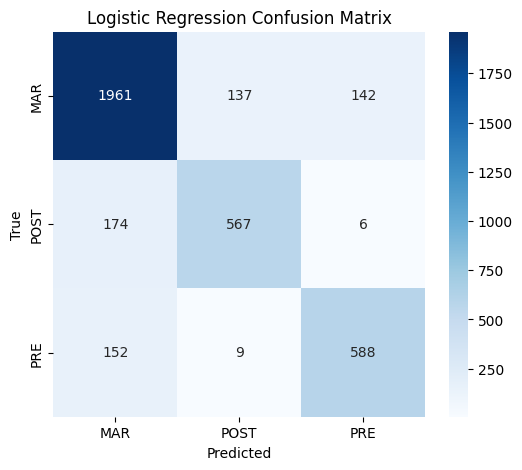


========== SVM ==========

Accuracy            : 0.8338
Precision (Macro)   : 0.8163
Recall (Macro)      : 0.8073
Macro F1 Score      : 0.8117
Balanced Accuracy   : 0.8073


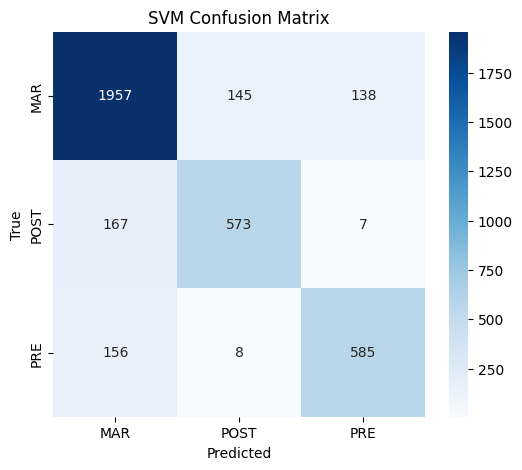


========== Random Forest ==========

Accuracy            : 0.8386
Precision (Macro)   : 0.8241
Recall (Macro)      : 0.8096
Macro F1 Score      : 0.8166
Balanced Accuracy   : 0.8096


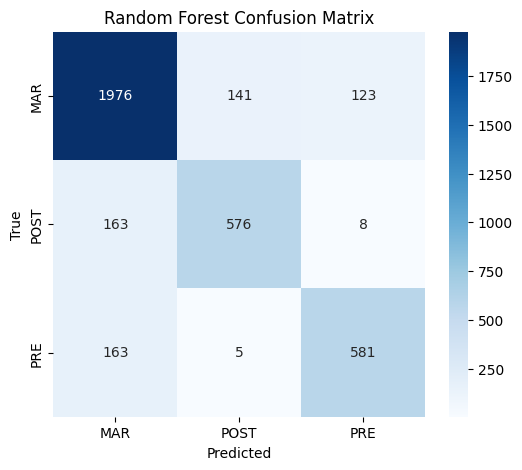


========== XGBoost ==========



/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [09:51:49] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Accuracy            : 0.8373
Precision (Macro)   : 0.8206
Recall (Macro)      : 0.8113
Macro F1 Score      : 0.8157
Balanced Accuracy   : 0.8113


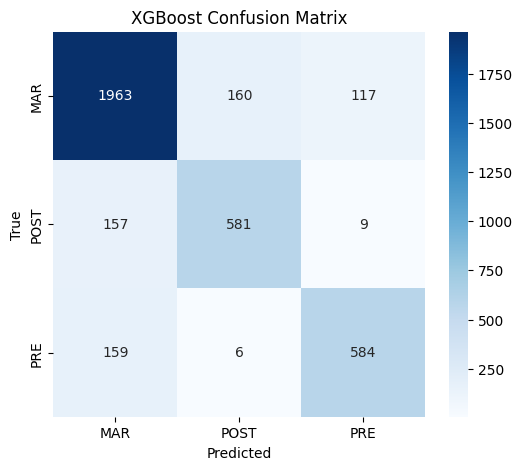


========== kNN ==========

Accuracy            : 0.8322
Precision (Macro)   : 0.8197
Recall (Macro)      : 0.7987
Macro F1 Score      : 0.8085
Balanced Accuracy   : 0.7987


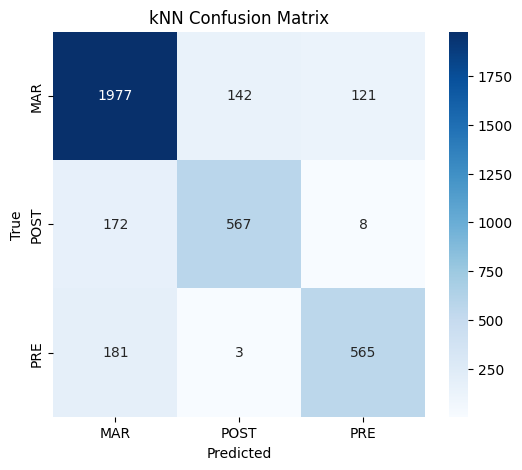


  CLASSIFIER EVALUATION ON LEARNED EMBEDDINGS

              Model  Accuracy  Precision   Recall  Macro F1  Balanced Accuracy
            XGBoost  0.837259   0.820552 0.811274  0.815701           0.811274
      Random Forest  0.838597   0.824060 0.809643  0.816551           0.809643
                SVM  0.833779   0.816320 0.807257  0.811669           0.807257
Logistic Regression  0.834047   0.817200 0.806510  0.811663           0.806510
                kNN  0.832173   0.819656 0.798655  0.808514           0.798655


In [25]:
# =========================================================
#  CLASSIFIER EVALUATION
# =========================================================

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

# ---------------------------------------------------------
# FEATURE EXTRACTION MODEL
# ---------------------------------------------------------

embedding_model = Model(
    inputs=model.inputs,
    outputs=model.layers[-2].output
)

train_embeddings = embedding_model.predict(
    [Xe_tr, Xc_tr, Xm_tr],
    verbose=0
)

test_embeddings = embedding_model.predict(
    [Xe_te, Xc_te, Xm_te],
    verbose=0
)

print("Train Embedding Shape :", train_embeddings.shape)
print("Test Embedding Shape  :", test_embeddings.shape)

# =========================================================
# CLASSIFIERS
# =========================================================

embedding_classifiers = {

    "Logistic Regression":
        LogisticRegression(max_iter=1000),

    "SVM":
        SVC(),

    "Random Forest":
        RandomForestClassifier(random_state=42),

    "XGBoost":
        XGBClassifier(
            use_label_encoder=False,
            eval_metric="mlogloss",
            random_state=42
        ),

    "kNN":
        KNeighborsClassifier()
}

results = []

print("\n===================================================")
print("  CLASSIFIER EVALUATION ON LEARNED EMBEDDINGS")
print("===================================================\n")

for name, clf in embedding_classifiers.items():

    print(f"\n========== {name} ==========\n")

    # -----------------------------------------------------
    # Train classifier
    # -----------------------------------------------------

    clf.fit(train_embeddings, y_tr)

    # -----------------------------------------------------
    # Predict
    # -----------------------------------------------------

    preds = clf.predict(test_embeddings)

    # -----------------------------------------------------
    # Metrics
    # -----------------------------------------------------

    acc = accuracy_score(y_te, preds)

    prec = precision_score(
        y_te,
        preds,
        average="macro"
    )

    rec = recall_score(
        y_te,
        preds,
        average="macro"
    )

    f1 = f1_score(
        y_te,
        preds,
        average="macro"
    )

    bal_acc = balanced_accuracy_score(
        y_te,
        preds
    )

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "Macro F1": f1,
        "Balanced Accuracy": bal_acc
    })

    print(f"Accuracy            : {acc:.4f}")
    print(f"Precision (Macro)   : {prec:.4f}")
    print(f"Recall (Macro)      : {rec:.4f}")
    print(f"Macro F1 Score      : {f1:.4f}")
    print(f"Balanced Accuracy   : {bal_acc:.4f}")

    # -----------------------------------------------------
    # Confusion Matrix
    # -----------------------------------------------------

    cm = confusion_matrix(y_te, preds)

    plt.figure(figsize=(6,5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes
    )

    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.savefig(
    os.path.join(IMG_DIR, "obj2_classifiers.png"),
    dpi=600,
    bbox_inches="tight"
    )

    plt.show()

# =========================================================
# RESULTS TABLE
# =========================================================

results_df = pd.DataFrame(results)

results_df.to_csv(
    os.path.join(
        CSV_DIR,
        "Classifier_Evaluation.csv"
    ),
    index=False
)

results_df = results_df.sort_values(
    by="Balanced Accuracy",
    ascending=False
)

print("\n===================================================")
print("  CLASSIFIER EVALUATION ON LEARNED EMBEDDINGS")
print("===================================================\n")

print(results_df.to_string(index=False))

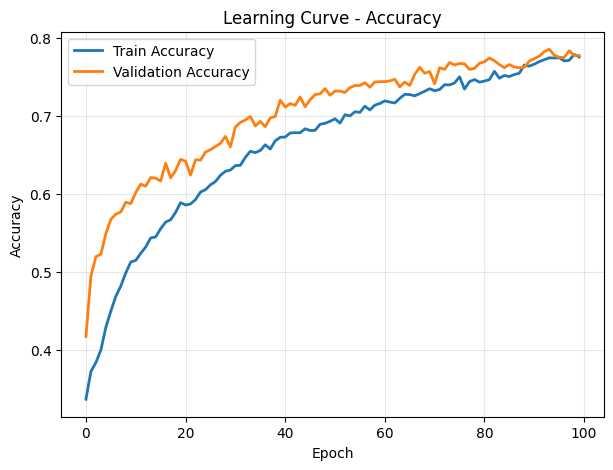

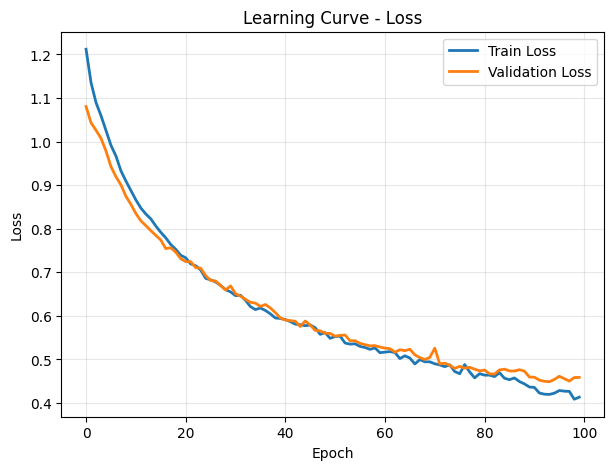

In [26]:
# =========================================================
# LEARNING CURVES
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    history.history['accuracy'],
    label='Train Accuracy',
    linewidth=2
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy',
    linewidth=2
)

plt.title("Learning Curve - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    os.path.join(IMG_DIR, "obj2_LC_Accuracy.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()


plt.figure(figsize=(7,5))

plt.plot(
    history.history['loss'],
    label='Train Loss',
    linewidth=2
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss',
    linewidth=2
)

plt.title("Learning Curve - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(alpha=0.3)
plt.savefig(
    os.path.join(IMG_DIR, "obj2_LC_loss.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# Save Objective 2 curve data for the combined 2x2 figure
obj2_train_acc = history.history['accuracy'].copy()
obj2_val_acc   = history.history['val_accuracy'].copy()
obj2_train_loss = history.history['loss'].copy()
obj2_val_loss   = history.history['val_loss'].copy()

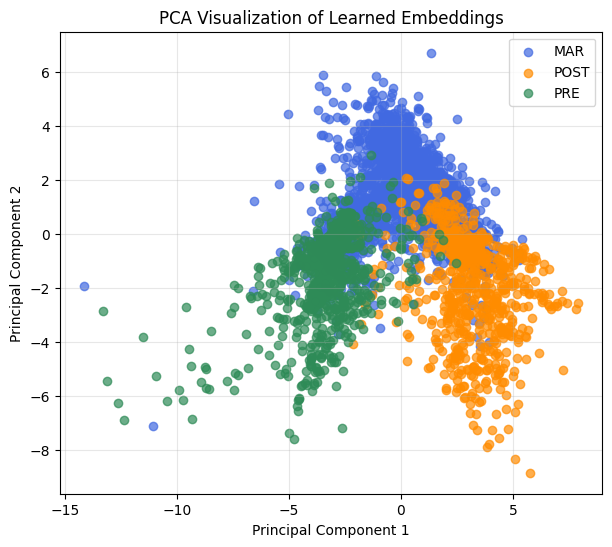

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


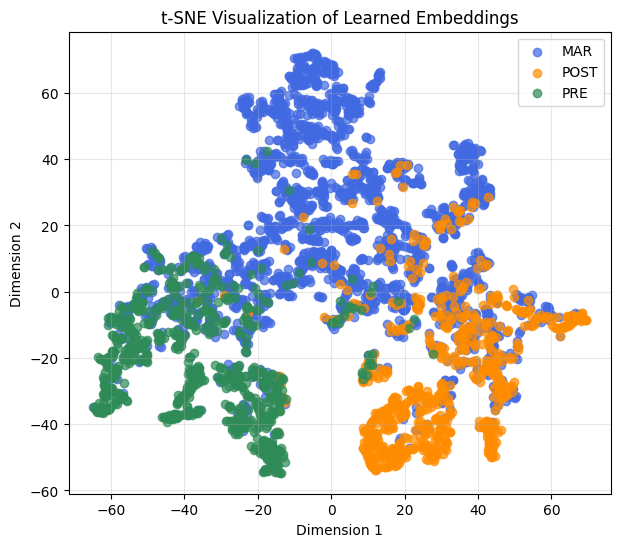

In [27]:
# =========================================================
# PCA + t-SNE
# =========================================================

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
emb_scaled = StandardScaler().fit_transform(test_embeddings)

# =========================================================
# PCA
# =========================================================

pca = PCA(
    n_components=2,
    random_state=42
)

emb_pca = pca.fit_transform(emb_scaled)

plt.figure(figsize=(7,6))

colors = ["royalblue", "darkorange", "seagreen"]

for cls, color in zip(np.unique(y_te), colors):

    idx = y_te == cls

    plt.scatter(
        emb_pca[idx, 0],
        emb_pca[idx, 1],
        c=color,
        label=classes[cls],
        alpha=0.7
    )

plt.title("PCA Visualization of Learned Embeddings")

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend()

plt.grid(alpha=0.3)

plt.savefig(
    os.path.join(IMG_DIR, "obj2_PCA.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# =========================================================
# t-SNE
# =========================================================

pca50 = PCA(
    n_components=min(50, emb_scaled.shape[1]),
    random_state=42
)

emb_reduced = pca50.fit_transform(emb_scaled)

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    n_iter=1000
)

emb_tsne = tsne.fit_transform(emb_reduced)

plt.figure(figsize=(7,6))

for cls, color in zip(np.unique(y_te), colors):

    idx = y_te == cls

    plt.scatter(
        emb_tsne[idx,0],
        emb_tsne[idx,1],
        c=color,
        label=classes[cls],
        alpha=0.7
    )

plt.title("t-SNE Visualization of Learned Embeddings")

plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")

plt.legend()

plt.grid(alpha=0.3)

plt.savefig(
    os.path.join(IMG_DIR, "obj2_t-SNE.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

Running: EEG + ECG + EMG
Accuracy: 0.7073 | Macro F1: 0.7050
Running: EEG + ECG
Accuracy: 0.6511 | Macro F1: 0.6520
Running: EEG + EMG
Accuracy: 0.6701 | Macro F1: 0.6712
Running: EEG Only
Accuracy: 0.5957 | Macro F1: 0.6013
Running: ECG + EMG
Accuracy: 0.5023 | Macro F1: 0.5188
Running: ECG Only
Accuracy: 0.3484 | Macro F1: 0.3607
Running: EMG Only
Accuracy: 0.4038 | Macro F1: 0.4114

   Configuration  Accuracy  Macro F1
EEG + ECG + EMG  0.707252  0.705024
      EEG + ECG  0.651057  0.651998
      EEG + EMG  0.670056  0.671224
       EEG Only  0.595665  0.601254
      ECG + EMG  0.502275  0.518758
       ECG Only  0.348408  0.360662
       EMG Only  0.403800  0.411431


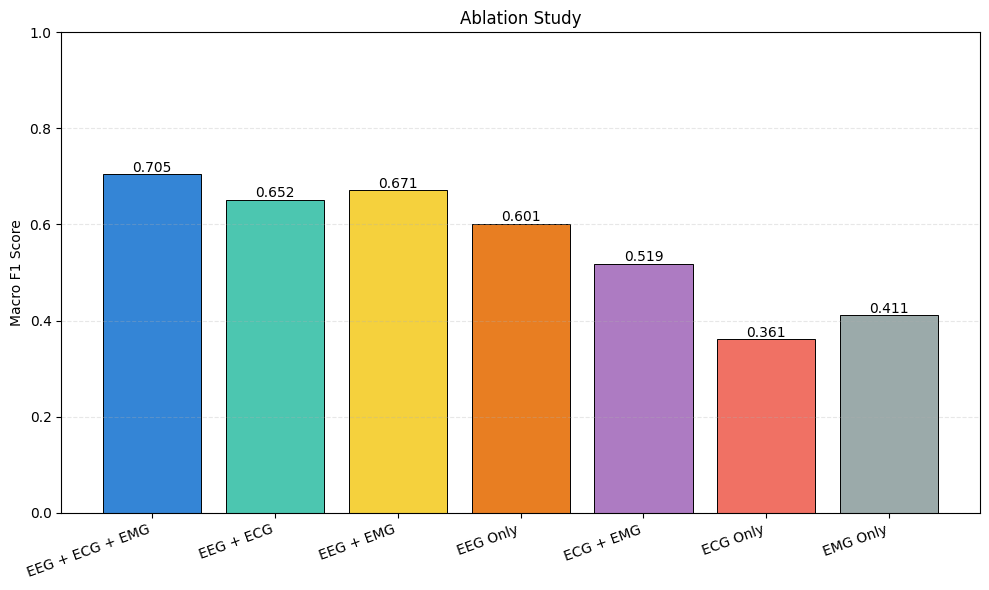

In [28]:
# =========================================================
# ABLATION STUDY
# =========================================================
fusion_df = pd.read_csv(
    os.path.join(BASE_DIR, "Fusion_features.csv")
)

meta_cols = [
    "file_name", "phase", "window_id", "sample_rate",
    "split_mode", "subject_id", "usable_duration_sec",
    "window_start_in_phase", "window_end_in_phase",
    "window_start_global", "window_end_global"
]

feature_df = fusion_df.drop(
    columns=[c for c in meta_cols if c in fusion_df.columns],
    errors="ignore"
).select_dtypes(include=np.number)

feature_df = feature_df.replace([np.inf, -np.inf], np.nan)
feature_df = feature_df.dropna(axis=1, how="all")

eeg_cols = [
    c for c in feature_df.columns
    if c.startswith(("FP1_", "FP2_", "T3_", "T4_", "C3_", "C4_", "O1_", "O2_"))
]
ecg_cols = [c for c in feature_df.columns if c.startswith("ECG_")]
emg_cols = [c for c in feature_df.columns if c.startswith("EMG_")]

assert (len(eeg_cols), len(ecg_cols), len(emg_cols)) == (160, 16, 19), \
    "Check EEG, ECG and EMG feature grouping."

y_ablation = LabelEncoder().fit_transform(fusion_df["phase"].astype(str))
classes_ablation = np.unique(y_ablation)

configs = {
    "EEG + ECG + EMG": eeg_cols + ecg_cols + emg_cols,
    "EEG + ECG": eeg_cols + ecg_cols,
    "EEG + EMG": eeg_cols + emg_cols,
    "EEG Only": eeg_cols,
    "ECG + EMG": ecg_cols + emg_cols,
    "ECG Only": ecg_cols,
    "EMG Only": emg_cols
}

train_idx, test_idx = train_test_split(
    np.arange(len(y_ablation)),
    test_size=0.20,
    stratify=y_ablation,
    random_state=42
)

y_train_ab = y_ablation[train_idx]
y_test_ab = y_ablation[test_idx]

def evaluate_configuration(feature_names):

    X = feature_df[feature_names].to_numpy(dtype=np.float32)
    X_train_raw, X_test_raw = X[train_idx].copy(), X[test_idx].copy()

    medians = np.nanmedian(X_train_raw, axis=0)
    medians = np.where(np.isfinite(medians), medians, 0.0)

    X_train_raw = np.where(np.isfinite(X_train_raw), X_train_raw, medians)
    X_test_raw = np.where(np.isfinite(X_test_raw), X_test_raw, medians)

    scaler = StandardScaler()
    X_train_ab = scaler.fit_transform(X_train_raw)
    X_test_ab = scaler.transform(X_test_raw)

    class_ids = np.unique(y_train_ab)
    weights = compute_class_weight(
        class_weight="balanced",
        classes=class_ids,
        y=y_train_ab
    )
    cw_dict = {int(c): float(w) for c, w in zip(class_ids, weights)}

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    inp = Input(shape=(X_train_ab.shape[1],))

    x = Dense(64)(inp)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Dropout(0.30)(x)

    x = Dense(32)(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Dropout(0.30)(x)

    x = Dense(32, activation="relu")(x)
    x = Dropout(0.30)(x)

    x = Dense(16, activation="relu")(x)
    x = Dropout(0.20)(x)

    out = Dense(len(classes_ablation), activation="softmax")(x)

    abl_model = Model(inp, out)
    abl_model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    abl_model.fit(
        X_train_ab,
        y_train_ab,
        validation_split=0.15,
        epochs=40,
        batch_size=256,
        verbose=0,
        class_weight=cw_dict,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True
            )
        ]
    )

    preds = np.argmax(abl_model.predict(X_test_ab, verbose=0), axis=1)

    acc = accuracy_score(y_test_ab, preds)
    f1 = f1_score(y_test_ab, preds, average="macro", zero_division=0)

    tf.keras.backend.clear_session()
    return acc, f1

ablation_results = []

for name, selected_cols in configs.items():
    print(f"Running: {name}")
    acc, f1 = evaluate_configuration(selected_cols)
    print(f"Accuracy: {acc:.4f} | Macro F1: {f1:.4f}")

    ablation_results.append({
        "Configuration": name,
        "Accuracy": acc,
        "Macro F1": f1
    })

ablation_df = pd.DataFrame(ablation_results)

ablation_df.to_csv(
    os.path.join(CSV_DIR, "Ablation_Study.csv"),
    index=False
)

print("\n", ablation_df.to_string(index=False))

colour_map = [
    "#3485D6", "#4CC6B0", "#F5D13D", "#E87E22",
    "#AD7BC2", "#F07164", "#9BAAAA"
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    ablation_df["Configuration"],
    ablation_df["Macro F1"],
    color=colour_map,
    edgecolor="black",
    linewidth=0.7
)

for bar in bars:
    h = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        h + 0.005,
        f"{h:.3f}",
        ha="center",
        fontsize=10
    )

plt.title("Ablation Study")
plt.ylabel("Macro F1 Score")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(IMG_DIR, "obj2_Ablationstudy.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()


#objective 3


In [29]:
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    BatchNormalization,
    Activation,
    Input,
    Concatenate,
    Multiply,
    Add
)

In [30]:
def modality_branch(inp, units1=64, units2=32):

    # =========================
    # FEATURE ATTENTION GATE
    # =========================
    gate = Dense(
        int(inp.shape[-1]),
        activation="sigmoid",
        name=f"{inp.name.split(':')[0]}_gate"
    )(inp)

    gated = Multiply(name=f"{inp.name.split(':')[0]}_multiply")([inp, gate])

    # =========================
    # FEATURE ENCODER
    # =========================
    x = Dense(units1)(gated)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Dropout(0.30)(x)

    x = Dense(units2)(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Dropout(0.25)(x)

    return x

In [31]:
def build_obj3(dim_eeg, dim_ecg, dim_emg, n_classes):

    # =========================
    # INPUTS
    # =========================
    eeg_in = Input(shape=(dim_eeg,), name="EEG_Input")
    ecg_in = Input(shape=(dim_ecg,), name="ECG_Input")
    emg_in = Input(shape=(dim_emg,), name="EMG_Input")

    # =========================
    # MODALITY ENCODERS
    # =========================
    eeg = modality_branch(eeg_in, 64, 32)
    ecg = modality_branch(ecg_in, 64, 32)
    emg = modality_branch(emg_in, 64, 32)

    # =========================
    # MULTIMODAL FUSION
    # =========================
    fusion = Concatenate(name="Fusion_Layer")([eeg, ecg, emg])

    # =========================
    # FUSION ATTENTION
    # =========================
    fusion_attn = Dense(
        96,
        activation="sigmoid",
        name="Fusion_Attention"
    )(fusion)

    attended = Multiply(name="Fusion_Multiply")([fusion, fusion_attn])

    # =========================
    # RESIDUAL ENHANCEMENT
    # =========================
    fusion_out = Add(name="Residual_Add")([fusion, attended])

    # =========================
    # CLASSIFIER
    # =========================
    x = Dense(64)(fusion_out)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Dropout(0.30)(x)

    x = Dense(32)(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Dropout(0.20)(x)

    out = Dense(
        n_classes,
        activation="softmax",
        name="Output_Layer"
    )(x)

    model = Model(
        [eeg_in, ecg_in, emg_in],
        out,
        name="Attention_Gated_Multimodal_Fusion_Network"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(8e-4),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [32]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_acc = []
fold_bal = []
fold_f1 = []

train_acc_histories = []
val_acc_histories = []

train_loss_histories = []
val_loss_histories = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X_eeg, y), start=1):

    print(f"\n========== Fold {fold} ==========")

    Xe_tr, Xe_te = X_eeg[train_idx], X_eeg[test_idx]
    Xc_tr, Xc_te = X_ecg[train_idx], X_ecg[test_idx]
    Xm_tr, Xm_te = X_emg[train_idx], X_emg[test_idx]

    y_tr, y_te = y[train_idx], y[test_idx]

    # =========================
    # STANDARDIZATION
    # =========================
    s1, s2, s3 = StandardScaler(), StandardScaler(), StandardScaler()

    Xe_tr = s1.fit_transform(Xe_tr)
    Xe_te = s1.transform(Xe_te)

    Xc_tr = s2.fit_transform(Xc_tr)
    Xc_te = s2.transform(Xc_te)

    Xm_tr = s3.fit_transform(Xm_tr)
    Xm_te = s3.transform(Xm_te)

    # =========================
    # VALIDATION SPLIT
    # =========================
    Xe_train, Xe_val, \
    Xc_train, Xc_val, \
    Xm_train, Xm_val, \
    y_train, y_val = train_test_split(

        Xe_tr,
        Xc_tr,
        Xm_tr,
        y_tr,

        test_size=0.15,
        stratify=y_tr,
        random_state=42 + fold
    )

    # =========================
    # CLASS WEIGHTS
    # =========================
    vals = np.unique(y_train)

    cw = compute_class_weight(
        class_weight="balanced",
        classes=vals,
        y=y_train
    )

    cw_dict = {
        int(c): float(w)
        for c, w in zip(vals, cw)
    }

    tf.keras.backend.clear_session()

    # =========================
    # BUILD MODEL
    # =========================
    model = build_obj3(
        Xe_tr.shape[1],
        Xc_tr.shape[1],
        Xm_tr.shape[1],
        len(classes)
    )

    # =========================
    # CALLBACKS
    # =========================
    cb = [

        EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=5,
            min_lr=1e-5
        )
    ]

    # =========================
    # TRAINING
    # =========================
    history = model.fit(

        [Xe_train, Xc_train, Xm_train],
        y_train,

        validation_data=(
            [Xe_val, Xc_val, Xm_val],
            y_val
        ),


        epochs=100,
        batch_size=128,

        class_weight=cw_dict,

        callbacks=cb,

        verbose=1
    )

    train_acc_histories.append(history.history["accuracy"])

    val_acc_histories.append(history.history["val_accuracy"])

    train_loss_histories.append(history.history["loss"])
    val_loss_histories.append(history.history["val_loss"])

    # =========================
    # PREDICTION
    # =========================
    pred = np.argmax(
        model.predict(
            [Xe_te, Xc_te, Xm_te],
            verbose=0
        ),
        axis=1
    )

    acc = accuracy_score(y_te, pred)
    bal = balanced_accuracy_score(y_te, pred)
    f1 = f1_score(y_te, pred, average="macro")

    print("ACC :", round(acc,4))
    print("BAL :", round(bal,4))
    print("F1  :", round(f1,4))

    fold_acc.append(acc)
    fold_bal.append(bal)
    fold_f1.append(f1)


========== Fold 1 ==========
Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 30s 139ms/step - accuracy: 0.3609 - loss: 1.2157 - val_accuracy: 0.4090 - val_loss: 1.0540 - learning_rate: 8.0000e-04
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3880 - loss: 1.1050 - val_accuracy: 0.4469 - val_loss: 1.0311 - learning_rate: 8.0000e-04
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4069 - loss: 1.0597 - val_accuracy: 0.5062 - val_loss: 0.9902 - learning_rate: 8.0000e-04
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4280 - loss: 1.0206 - val_accuracy: 0.5294 - val_loss: 0.9599 - learning_rate: 8.0000e-04
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4557 - loss: 0.9635 - val_accuracy: 0.5250 - val_loss: 0.9224 - learning_rate: 8.0000e-04
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4800 - loss: 0.9155 - val_accuracy: 0.5553 - val_loss: 0.8720 - learning_rate: 8.0000e-04
Epoch 7/100
100/100 ━━━━━

In [33]:
#16
print("\n========== OBJECTIVE 3 FINAL ==========")

print("Mean Accuracy        :", round(np.mean(fold_acc),4))
print("Mean Balanced Acc    :", round(np.mean(fold_bal),4))
print("Mean Macro F1        :", round(np.mean(fold_f1),4))



========== OBJECTIVE 3 FINAL ==========
Mean Accuracy        : 0.8444
Mean Balanced Acc    : 0.875
Mean Macro F1        : 0.8345


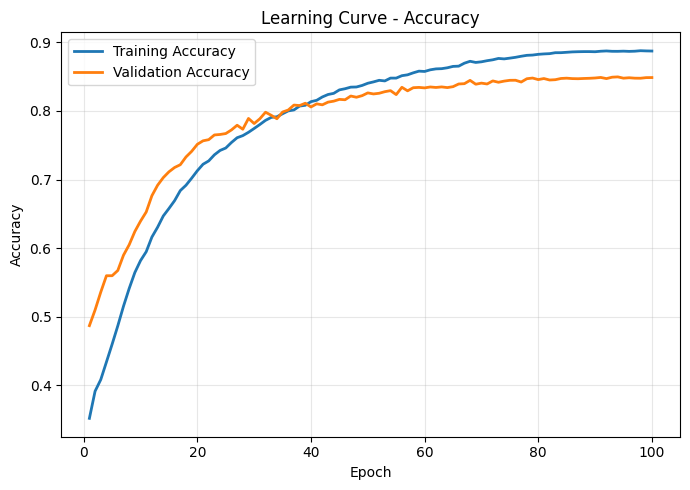

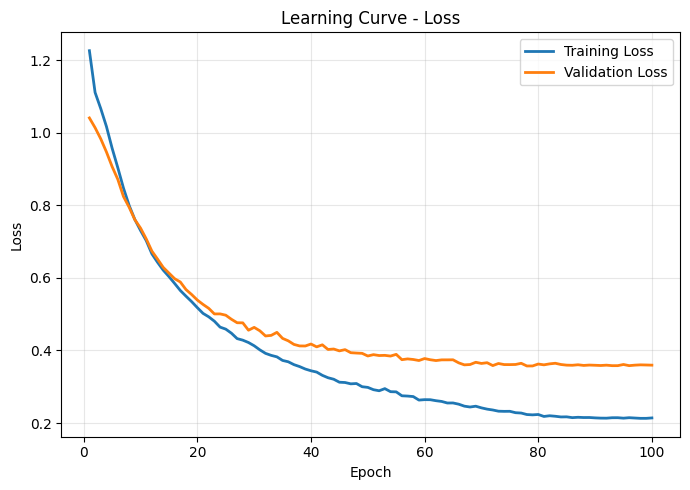

In [34]:

# =========================================================
# LEARNING CURVES
# =========================================================

import numpy as np
import matplotlib.pyplot as plt

def pad_histories(histories):

    max_len = max(len(h) for h in histories)

    padded = []

    for h in histories:

        if len(h) < max_len:

            h = h + [h[-1]] * (max_len - len(h))

        padded.append(h)

    return np.array(padded)

# ---------------------------------------------------------
# PAD
# ---------------------------------------------------------

train_acc = pad_histories(train_acc_histories)
val_acc   = pad_histories(val_acc_histories)

train_loss = pad_histories(train_loss_histories)
val_loss   = pad_histories(val_loss_histories)

# ---------------------------------------------------------
# MEAN CURVES
# ---------------------------------------------------------

mean_train_acc = train_acc.mean(axis=0)
mean_val_acc   = val_acc.mean(axis=0)

mean_train_loss = train_loss.mean(axis=0)
mean_val_loss   = val_loss.mean(axis=0)

epochs = np.arange(1, len(mean_train_acc)+1)

# =========================================================
# ACCURACY CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    epochs,
    mean_train_acc,
    linewidth=2,
    label="Training Accuracy"
)

plt.plot(
    epochs,
    mean_val_acc,
    linewidth=2,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.title("Learning Curve - Accuracy")

plt.grid(alpha=0.30)

plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        IMG_DIR,
        "obj3_LearningCurve_Accuracy.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# =========================================================
# LOSS CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    epochs,
    mean_train_loss,
    linewidth=2,
    label="Training Loss"
)

plt.plot(
    epochs,
    mean_val_loss,
    linewidth=2,
    label="Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Learning Curve - Loss")

plt.grid(alpha=0.30)

plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        IMG_DIR,
        "obj3_LearningCurve_Loss.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# Save Objective 3 curve data for the combined 2x2 figure
obj3_train_acc = mean_train_acc
obj3_val_acc   = mean_val_acc
obj3_train_loss = mean_train_loss
obj3_val_loss   = mean_val_loss

In [36]:
print("\n========== MODEL ARCHITECTURE ==========")

model.summary()

print("\n========== MODEL LAYERS ==========")

for i, layer in enumerate(model.layers):
    print(f"{i+1}. {layer.name}")


========== MODEL ARCHITECTURE ==========


Model: "Attention_Gated_Multimodal_Fusion_Network"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ EEG_Input           │ (None, 160)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ECG_Input           │ (None, 16)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EMG_Input           │ (None, 19)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EEG_Input_gate      │ (None, 160)       │     25,760 │ EEG_Input[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ECG_Input_gate      │ (None, 16)        │        272 │ ECG_Input[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EMG_Input_gate      │ (None, 19)        │        380 │ EMG_Input[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EEG_Input_multiply  │ (None, 160)       │          0 │ EEG_Input[0][0],  │
│ (Multiply)          │                   │            │ EEG_Input_gate[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ECG_Input_multiply  │ (None, 16)        │          0 │ ECG_Input[0][0],  │
│ (Multiply)          │                   │            │ ECG_Input_gate[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EMG_Input_multiply  │ (None, 19)        │          0 │ EMG_Input[0][0],  │
│ (Multiply)          │                   │            │ EMG_Input_gate[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │     10,304 │ EEG_Input_multip… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      1,088 │ ECG_Input_multip… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64)        │      1,280 │ EMG_Input_multip… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64)        │        256 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_2[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_4[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 64)        │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64)        │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 64)        │          0 │ batch_normalizat

 Total params: 192,143 (750.56 KB)

 Trainable params: 63,791 (249.18 KB)

 Non-trainable params: 768 (3.00 KB)

 Optimizer params: 127,584 (498.38 KB)


========== MODEL LAYERS ==========
1. EEG_Input
2. ECG_Input
3. EMG_Input
4. EEG_Input_gate
5. ECG_Input_gate
6. EMG_Input_gate
7. EEG_Input_multiply
8. ECG_Input_multiply
9. EMG_Input_multiply
10. dense
11. dense_2
12. dense_4
13. batch_normalization
14. batch_normalization_2
15. batch_normalization_4
16. activation
17. activation_2
18. activation_4
19. dropout
20. dropout_2
21. dropout_4
22. dense_1
23. dense_3
24. dense_5
25. batch_normalization_1
26. batch_normalization_3
27. batch_normalization_5
28. activation_1
29. activation_3
30. activation_5
31. dropout_1
32. dropout_3
33. dropout_5
34. Fusion_Layer
35. Fusion_Attention
36. Fusion_Multiply
37. Residual_Add
38. dense_6
39. batch_normalization_6
40. activation_6
41. dropout_6
42. dense_7
43. batch_normalization_7
44. activation_7
45. dropout_7
46. Output_Layer


In [37]:
attention_model = Model(

    inputs=model.inputs,

    outputs=[

        model.get_layer("EEG_Input_gate").output,
        model.get_layer("ECG_Input_gate").output,
        model.get_layer("EMG_Input_gate").output,

        model.get_layer("Fusion_Attention").output
    ]
)

g_eeg, g_ecg, g_emg, g_fusion = attention_model.predict(

    [Xe_te, Xc_te, Xm_te],
    verbose=0
)

print("EEG Attention Shape :", g_eeg.shape)
print("ECG Attention Shape :", g_ecg.shape)
print("EMG Attention Shape :", g_emg.shape)
print("Fusion Attention Shape :", g_fusion.shape)

EEG Attention Shape : (3736, 160)
ECG Attention Shape : (3736, 16)
EMG Attention Shape : (3736, 19)
Fusion Attention Shape : (3736, 96)


In [38]:
def plot_clean_attention(gates, names, y_true, classes, title):

    mean_att = gates.mean(axis=0)

    # Save feature attention values
    all_attention_df = pd.DataFrame({
        "Feature": names,
        "Attention_Weight": mean_att
    })

    all_attention_df.to_csv(
        os.path.join(
            ANALYSIS_DIR,
            f"{title}_Attention_All.csv"
        ),
        index=False
    )

    top_k = min(15, len(names))

    top_idx = np.argsort(mean_att)[-top_k:]

    top_names = [names[i] for i in top_idx]
    top_vals  = mean_att[top_idx]

    attention_df = pd.DataFrame({
        "Feature": top_names,
        "Attention_Weight": top_vals
    })

    attention_df.to_csv(
        os.path.join(
            ANALYSIS_DIR,
            f"{title}_Attention_Top15.csv"
        ),
        index=False
    )

    # =========================
    # BAR PLOT
    # =========================
    plt.figure(figsize=(9,6))

    plt.barh(top_names, top_vals)

    plt.xlabel("Mean Attention Weight")
    plt.title(f"{title}: Top {top_k} Features by Attention")

    plt.tight_layout()

    plt.savefig(
    os.path.join(IMG_DIR, f"{title}_obj3_barplots.png"),
    dpi=600,
    bbox_inches="tight"
    )
    plt.show()

    # =========================
    # PHASE-WISE HEATMAP
    # =========================
    phase_mat = []

    for c in range(len(classes)):

        idx = np.where(y_true == c)[0]

        phase_mat.append(
            gates[idx][:, top_idx].mean(axis=0)
        )

    phase_mat = np.array(phase_mat)
    # Save heatmap data
    phase_df = pd.DataFrame(
        phase_mat,
        index=classes,
        columns=top_names
    )

    phase_df.to_csv(
        os.path.join(
            ANALYSIS_DIR,
            f"{title}_Attention_Heatmap.csv"
        )
    )

    plt.figure(figsize=(12,4))

    sns.heatmap(
        phase_mat,

        cmap="YlOrRd",

        xticklabels=top_names,
        yticklabels=classes,

        annot=True,
        fmt=".2f",

        cbar_kws={"label":"Mean Attention"}
    )

    plt.title(f"{title}: Phase-wise Feature Attention")

    plt.xlabel("Features")
    plt.ylabel("Phase")

    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()

    plt.savefig(
    os.path.join(IMG_DIR,
                 f"{title}_obj3_Phasewise.png"),
    dpi=600,
    bbox_inches="tight"
    )
    plt.show()

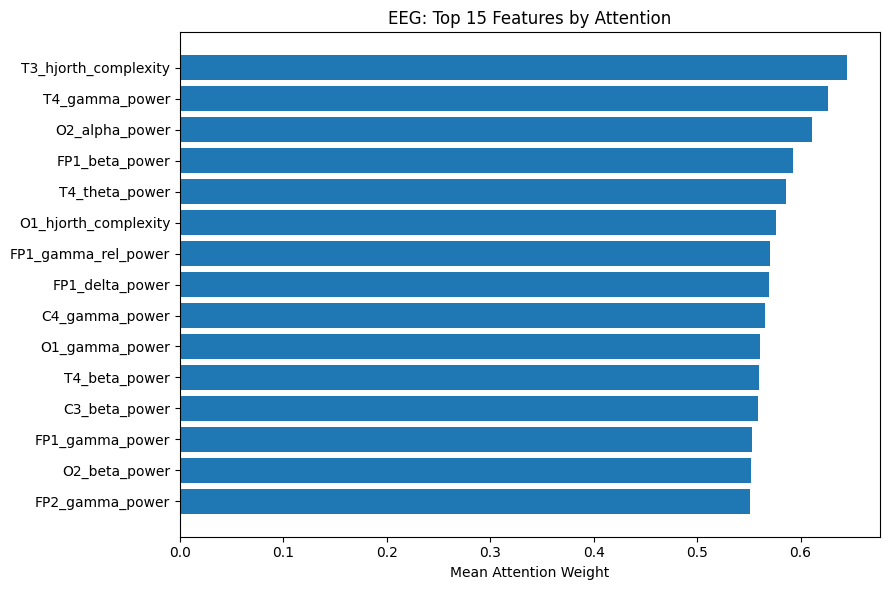

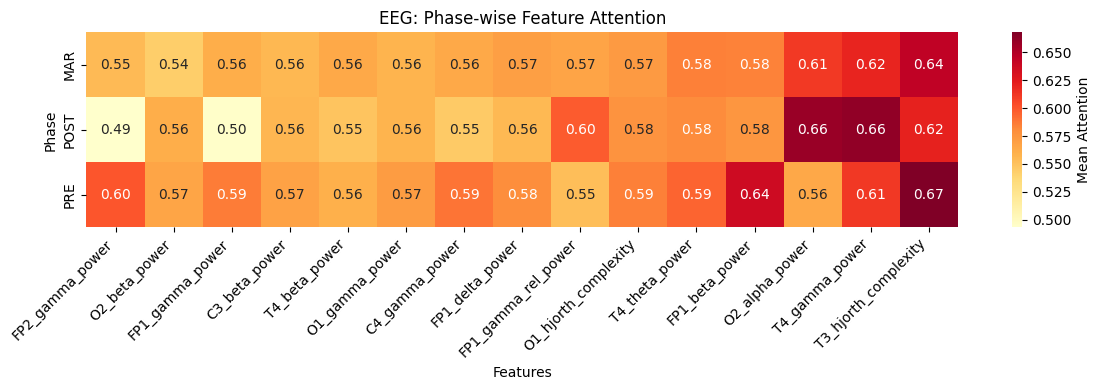

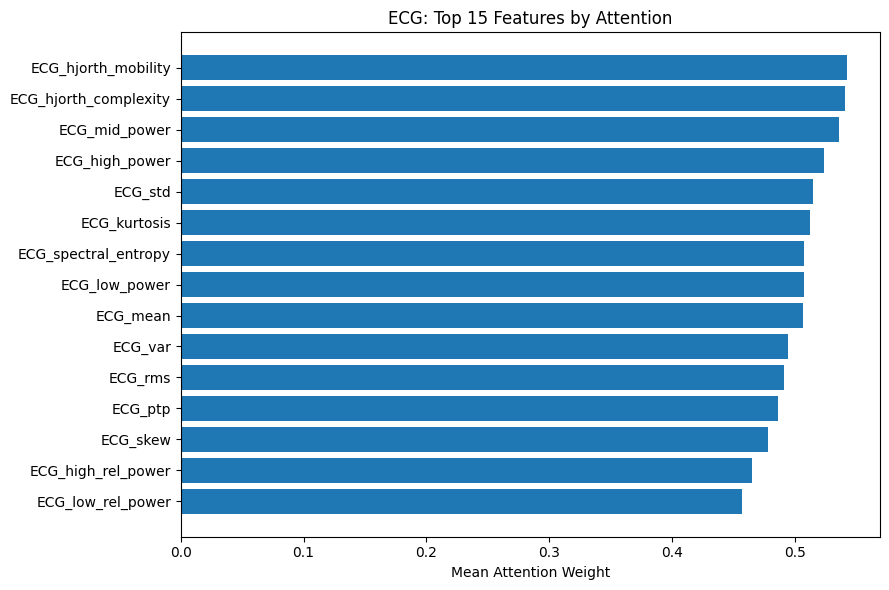

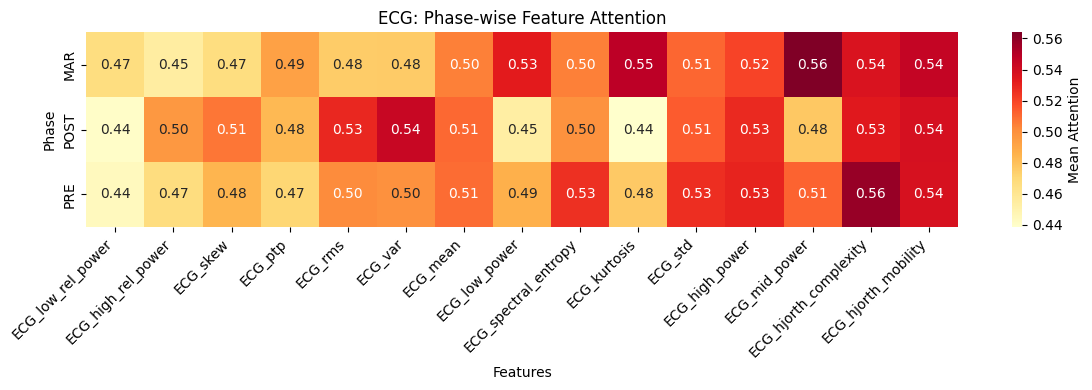

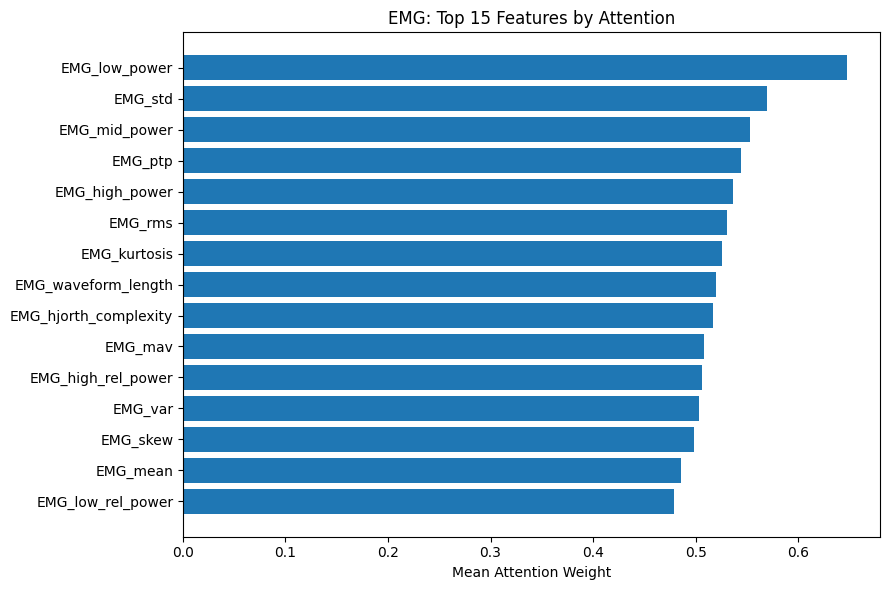

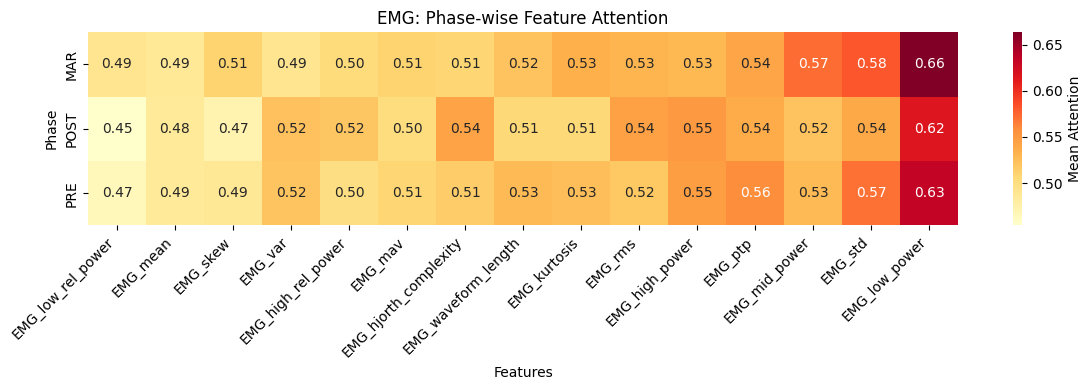

In [40]:
plot_clean_attention(
    g_eeg,
    eeg_names,
    y_te,
    classes,
    "EEG"
)

plot_clean_attention(
    g_ecg,
    ecg_names,
    y_te,
    classes,
    "ECG"
)

plot_clean_attention(
    g_emg,
    emg_names,
    y_te,
    classes,
    "EMG"
)


Fusion dataset shape: (18681, 198)
Fusion feature matrix: (18681, 195)
Number of original features: 195
Classes: ['MAR' 'POST' 'PRE']

Class distribution:
phase
MAR     11217
POST     3737
PRE      3727
Name: count, dtype: int64

========== FUSION FOLD 1 ==========
Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 16s 68ms/step - accuracy: 0.4263 - loss: 1.1121 - val_accuracy: 0.5745 - val_loss: 0.9187 - learning_rate: 8.0000e-04
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.4627 - loss: 0.9650 - val_accuracy: 0.5767 - val_loss: 0.8884 - learning_rate: 8.0000e-04
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5105 - loss: 0.8776 - val_accuracy: 0.5758 - val_loss: 0.8499 - learning_rate: 8.0000e-04
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5456 - loss: 0.8053 - val_accuracy: 0.6222 - val_loss: 0.7910 - learning_rate: 8.0000e-04
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5683 - loss: 0.7503 - val_accuracy: 

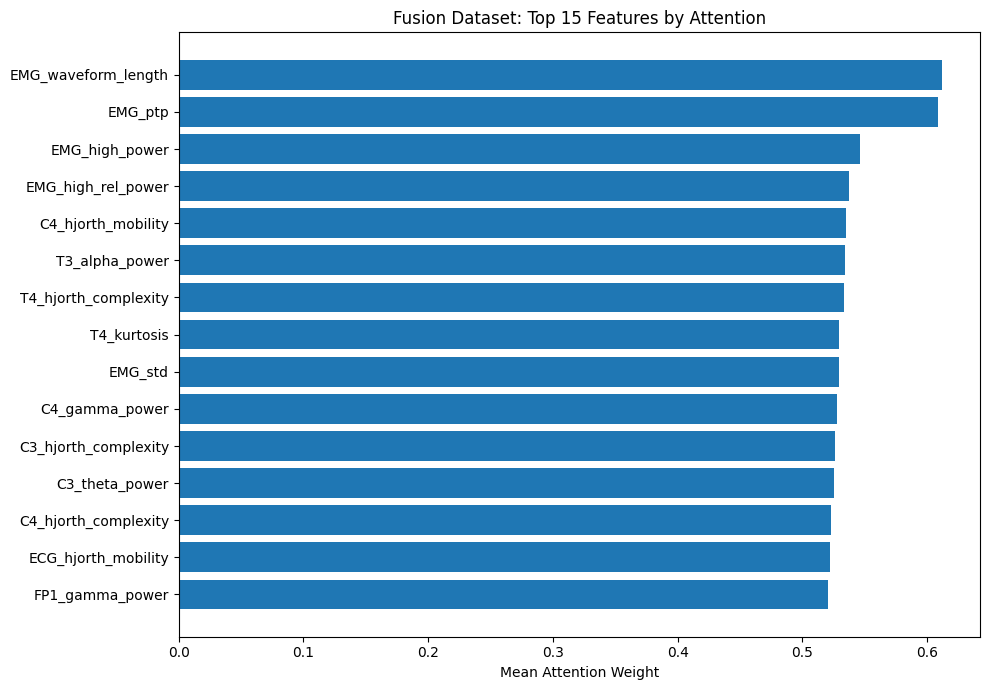

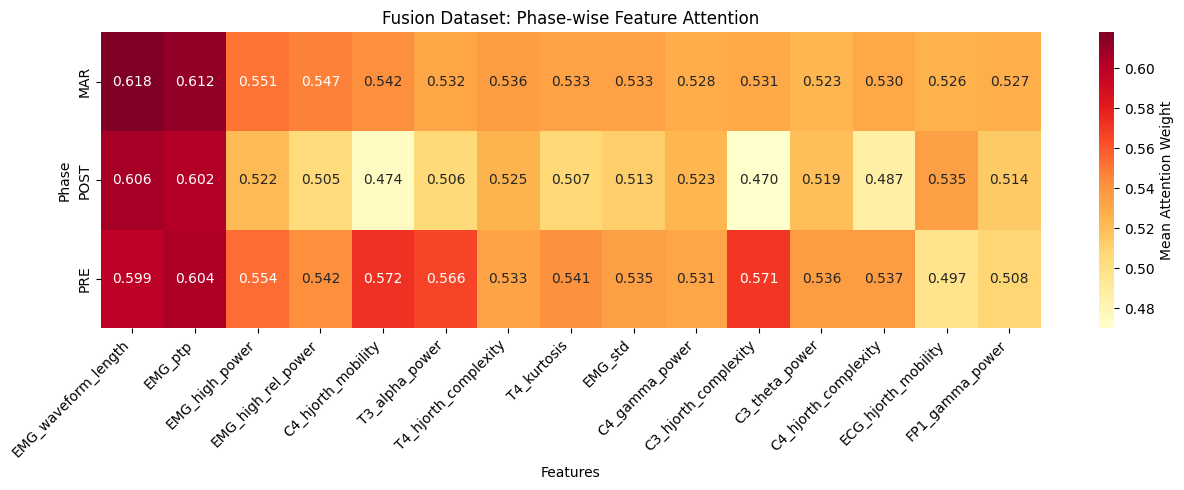


Fusion attention experiment completed.
Metrics: /content/drive/MyDrive/Sourcedata/Analysis/CSV/Fusion_Attention_CV_Results.csv
Feature results: /content/drive/MyDrive/Sourcedata/Analysis/Fusion_Attention_All_Features.csv
Plots saved in: /content/drive/MyDrive/Sourcedata/Analysis/Images


In [56]:
# ============================================================
# FUSION
# ============================================================

fusion_path = os.path.join(BASE_DIR, "Fusion_features.csv")
fusion_df = pd.read_csv(fusion_path)

print("Fusion dataset shape:", fusion_df.shape)

if "phase" not in fusion_df.columns:
    raise ValueError("The Fusion dataset has no 'phase' column.")

if fusion_df["phase"].isna().any():
    raise ValueError("The phase column contains missing values.")

# Remove metadata and target, retaining actual numerical features
meta_cols = [
    "file_name",
    "window_id",
    "sample_rate",
    "split_mode",
    "subject_id",
    "usable_duration_sec",
    "window_start_in_phase",
    "window_end_in_phase",
    "window_start_global",
    "window_end_global"
]

X_fusion_df = fusion_df.drop(
    columns=[
        c for c in meta_cols + ["phase"]
        if c in fusion_df.columns
    ],
    errors="ignore"
).select_dtypes(include=np.number)

X_fusion_df = X_fusion_df.replace(
    [np.inf, -np.inf], np.nan
)
X_fusion_df = X_fusion_df.dropna(axis=1, how="all")


fusion_feature_names = X_fusion_df.columns.tolist()


le_fusion = LabelEncoder()
y_fusion = le_fusion.fit_transform(
    fusion_df["phase"].astype(str)
)

X_fusion = X_fusion_df.to_numpy(dtype=np.float32)

print("Fusion feature matrix:", X_fusion.shape)
print("Number of original features:", len(fusion_feature_names))
print("Classes:", le_fusion.classes_)
print("\nClass distribution:")
print(fusion_df["phase"].value_counts())

if len(X_fusion) != len(y_fusion):
    raise ValueError("Fusion features and labels have different row counts.")
def build_fusion_attention_model(n_features, n_classes):

    fusion_input = Input(
        shape=(n_features,),
        name="Fusion_Input"
    )

    attention_gate = Dense(
        n_features,
        activation="sigmoid",
        name="Fusion_Feature_Attention"
    )(fusion_input)

    attended_features = Multiply(
        name="Fusion_Attention_Multiply"
    )([fusion_input, attention_gate])

    fusion_out = Add(
        name="Fusion_Residual_Add"
    )([fusion_input, attended_features])

    x = Dense(64, name="Fusion_Dense_64")(fusion_out)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Dropout(0.30)(x)

    x = Dense(32, name="Fusion_Dense_32")(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Dropout(0.20)(x)

    output = Dense(
        n_classes,
        activation="softmax",
        name="Output_Layer"
    )(x)

    fusion_model = Model(
        inputs=fusion_input,
        outputs=output,
        name="Fusion_Attention_Gated_MLP"
    )

    fusion_model.compile(
        optimizer=tf.keras.optimizers.Adam(8e-4),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return fusion_model


# ------------------------------------------------------------
# 3. FIVE-FOLD STRATIFIED CROSS-VALIDATION
# ------------------------------------------------------------

skf_fusion = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fusion_fold_acc = []
fusion_fold_bal = []
fusion_fold_f1 = []

fusion_oof_pred = np.full(len(y_fusion), -1, dtype=int)

fusion_oof_attention = np.full(
    (len(y_fusion), X_fusion.shape[1]),
    np.nan,
    dtype=np.float32
)

for fold, (train_idx, test_idx) in enumerate(
    skf_fusion.split(X_fusion, y_fusion), start=1
):

    print(f"\n========== FUSION FOLD {fold} ==========")

    X_train_raw = X_fusion[train_idx]
    X_test_raw = X_fusion[test_idx]

    y_train_full = y_fusion[train_idx]
    y_test = y_fusion[test_idx]
    train_medians = np.nanmedian(X_train_raw, axis=0)
    train_medians = np.where(
        np.isfinite(train_medians),
        train_medians,
        0.0
    )

    X_train_raw = np.where(
        np.isfinite(X_train_raw),
        X_train_raw,
        train_medians
    )

    X_test_raw = np.where(
        np.isfinite(X_test_raw),
        X_test_raw,
        train_medians
    )
    fusion_scaler = StandardScaler()

    X_train_scaled = fusion_scaler.fit_transform(X_train_raw)
    X_test_scaled = fusion_scaler.transform(X_test_raw)
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_scaled,
        y_train_full,
        test_size=0.15,
        stratify=y_train_full,
        random_state=42 + fold
    )
    fold_classes = np.unique(y_train)

    fold_weights = compute_class_weight(
        class_weight="balanced",
        classes=fold_classes,
        y=y_train
    )

    class_weights = {
        int(c): float(w)
        for c, w in zip(fold_classes, fold_weights)
    }

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42 + fold)

    fusion_model = build_fusion_attention_model(
        n_features=X_fusion.shape[1],
        n_classes=len(le_fusion.classes_)
    )

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=5,
            min_lr=1e-5
        )
    ]

    history = fusion_model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=128,
        class_weight=class_weights,
        callbacks=callbacks,
        verbose=1
    )

    probabilities = fusion_model.predict(
        X_test_scaled,
        verbose=0
    )

    predictions = np.argmax(probabilities, axis=1)

    acc = accuracy_score(y_test, predictions)
    bal = balanced_accuracy_score(y_test, predictions)
    macro_f1 = f1_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    fusion_fold_acc.append(acc)
    fusion_fold_bal.append(bal)
    fusion_fold_f1.append(macro_f1)

    fusion_oof_pred[test_idx] = predictions

    print("Accuracy         :", round(acc, 4))
    print("Balanced Accuracy:", round(bal, 4))
    print("Macro F1         :", round(macro_f1, 4))

    fusion_gate_model = Model(
        inputs=fusion_model.input,
        outputs=fusion_model.get_layer(
            "Fusion_Feature_Attention"
        ).output
    )

    fold_attention = fusion_gate_model.predict(
        X_test_scaled,
        verbose=0
    )

    fusion_oof_attention[test_idx] = fold_attention


# ------------------------------------------------------------
# 4. FINAL CROSS-VALIDATION RESULTS
# ------------------------------------------------------------

print("\n========== FUSION ATTENTION RESULTS ==========")

print(
    "Mean Accuracy         :",
    round(np.mean(fusion_fold_acc), 4),
    "+/-",
    round(np.std(fusion_fold_acc), 4)
)

print(
    "Mean Balanced Accuracy:",
    round(np.mean(fusion_fold_bal), 4),
    "+/-",
    round(np.std(fusion_fold_bal), 4)
)

print(
    "Mean Macro F1         :",
    round(np.mean(fusion_fold_f1), 4),
    "+/-",
    round(np.std(fusion_fold_f1), 4)
)

fusion_results_df = pd.DataFrame({
    "Fold": np.arange(1, 6),
    "Accuracy": fusion_fold_acc,
    "Balanced_Accuracy": fusion_fold_bal,
    "Macro_F1": fusion_fold_f1
})

fusion_results_df.to_csv(
    os.path.join(CSV_DIR, "Fusion_Attention_CV_Results.csv"),
    index=False
)

print("\nOut-of-fold classification report:")
print(
    classification_report(
        y_fusion,
        fusion_oof_pred,
        labels=np.arange(len(le_fusion.classes_)),
        target_names=le_fusion.classes_,
        zero_division=0
    )
)

# ------------------------------------------------------------
# 5. FEATURE-WISE ATTENTION IMPORTANCE
# ------------------------------------------------------------

if np.isnan(fusion_oof_attention).any():
    raise ValueError("Some out-of-fold attention values are missing.")
mean_fusion_attention = fusion_oof_attention.mean(axis=0)

fusion_attention_df = pd.DataFrame({
    "Feature": fusion_feature_names,
    "Mean_Attention_Weight": mean_fusion_attention
}).sort_values(
    "Mean_Attention_Weight",
    ascending=False
).reset_index(drop=True)

fusion_attention_df.to_csv(
    os.path.join(
        ANALYSIS_DIR,
        "Fusion_Attention_All_Features.csv"
    ),
    index=False
)

top15_fusion = fusion_attention_df.head(15).copy()

top15_fusion.to_csv(
    os.path.join(
        ANALYSIS_DIR,
        "Fusion_Attention_Top15.csv"
    ),
    index=False
)

print("\nTop 15 Fusion features by mean attention:")
print(top15_fusion.to_string(index=False))


# ------------------------------------------------------------
# 6. TOP-15 ATTENTION BAR PLOT
# ------------------------------------------------------------

plot_fusion = top15_fusion.sort_values(
    "Mean_Attention_Weight",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_fusion["Feature"],
    plot_fusion["Mean_Attention_Weight"]
)

plt.xlabel("Mean Attention Weight")
plt.ylabel("")
plt.title("Fusion Dataset: Top 15 Features by Attention")

plt.tight_layout()

plt.savefig(
    os.path.join(IMG_DIR, "Fusion_Attention_Top15.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. PHASE-WISE ATTENTION HEATMAP
# ------------------------------------------------------------

top_fusion_names = top15_fusion["Feature"].tolist()

top_fusion_indices = [
    fusion_feature_names.index(name)
    for name in top_fusion_names
]

phase_attention = []

for class_id in range(len(le_fusion.classes_)):

    class_mask = y_fusion == class_id

    class_mean = fusion_oof_attention[
        class_mask
    ][:, top_fusion_indices].mean(axis=0)

    phase_attention.append(class_mean)

phase_attention = np.asarray(phase_attention)

phase_attention_df = pd.DataFrame(
    phase_attention,
    index=le_fusion.classes_,
    columns=top_fusion_names
)

phase_attention_df.to_csv(
    os.path.join(
        ANALYSIS_DIR,
        "Fusion_Attention_Phasewise.csv"
    )
)

plt.figure(figsize=(13, 5))

sns.heatmap(
    phase_attention_df,
    cmap="YlOrRd",
    annot=True,
    fmt=".3f",
    cbar_kws={"label": "Mean Attention Weight"}
)

plt.title("Fusion Dataset: Phase-wise Feature Attention")
plt.xlabel("Features")
plt.ylabel("Phase")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    os.path.join(IMG_DIR, "Fusion_Attention_Phasewise.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("\nFusion attention experiment completed.")
print("Metrics:", os.path.join(CSV_DIR, "Fusion_Attention_CV_Results.csv"))
print("Feature results:", os.path.join(ANALYSIS_DIR, "Fusion_Attention_All_Features.csv"))
print("Plots saved in:", IMG_DIR)


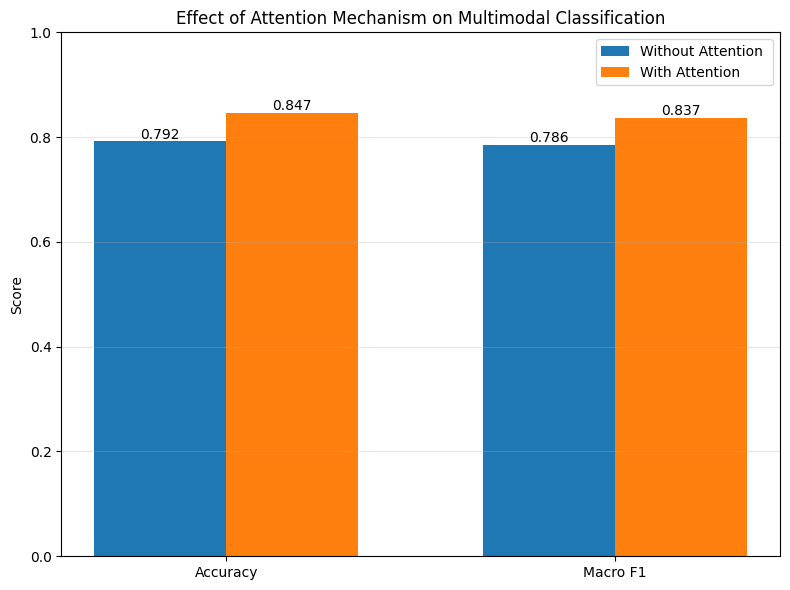

In [51]:
# =========================================================
# OBJECTIVE 2 vs OBJECTIVE 3
# WITHOUT ATTENTION vs WITH ATTENTION
# =========================================================

import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------------------------------
# METRICS
# ---------------------------------------------------------

metrics = [
    "Accuracy",

    "Macro F1"
]

# =========================================================
# ENTER YOUR FINAL VALUES
# =========================================================

obj2_scores = [
    0.7921,   # Accuracy
    0.7859   # Macro F1
]

obj3_scores = [
    0.8467,   # Accuracy
    0.8372   # Macro F1
]

# ---------------------------------------------------------
# BAR POSITIONS
# ---------------------------------------------------------

x = np.arange(len(metrics))

width = 0.34

# =========================================================
# PLOT
# =========================================================

plt.figure(figsize=(8,6))

bars1 = plt.bar(
    x - width/2,
    obj2_scores,
    width,
    label="Without Attention "
)

bars2 = plt.bar(
    x + width/2,
    obj3_scores,
    width,
    label="With Attention "
)

# ---------------------------------------------------------
# VALUE LABELS
# ---------------------------------------------------------

for bars in [bars1, bars2]:

    for b in bars:

        h = b.get_height()

        plt.text(
            b.get_x() + b.get_width()/2,
            h + 0.005,
            f"{h:.3f}",
            ha='center',
            fontsize=10
        )

# ---------------------------------------------------------
# FORMATTING
# ---------------------------------------------------------

plt.xticks(x, metrics)

plt.ylabel("Score")

plt.ylim(0, 1.0)

plt.title(
    "Effect of Attention Mechanism on Multimodal Classification"
)

plt.legend()

plt.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(IMG_DIR, "obj3_withand without attention.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

#objective 4


In [52]:
import shap
import numpy as np

bg_idx = np.random.choice(len(Xe_te), 100, replace=False)
ex_idx = np.random.choice(len(Xe_te), 30, replace=False)

background = [
    Xe_te[bg_idx],
    Xc_te[bg_idx],
    Xm_te[bg_idx]
]

samples = [
    Xe_te[ex_idx],
    Xc_te[ex_idx],
    Xm_te[ex_idx]
]

explainer = shap.DeepExplainer(
    model,
    background
)

# =========================================================
# SHAP VALUES
# =========================================================

shap_values = explainer.shap_values(samples)

print(type(shap_values))
print("Length :", len(shap_values))

for i, sv in enumerate(shap_values):

    print(f"\nModality {i}")

    print(np.array(sv).shape)

/usr/local/lib/python3.13/dist-packages/shap/explainers/_deep/deep_tf.py:94: UserWarning: Your TensorFlow version is newer than 2.4.0 and so graph support has been removed in eager mode and some static graphs may not be supported. See PR #1483 for discussion.
  warnings.warn(


<class 'list'>
Length : 3

Modality 0
(30, 160, 3)

Modality 1
(30, 16, 3)

Modality 2
(30, 19, 3)


In [53]:
# =========================================================
# CLEAN GLOBAL SHAP IMPORTANCE
# =========================================================

import numpy as np

# ---------------------------------------------------------
# GLOBAL IMPORTANCE
# ---------------------------------------------------------

eeg_imp = np.abs(shap_values[0]).mean(axis=(0,2))
ecg_imp = np.abs(shap_values[1]).mean(axis=(0,2))
emg_imp = np.abs(shap_values[2]).mean(axis=(0,2))

print("EEG importance shape :", eeg_imp.shape)
print("ECG importance shape :", ecg_imp.shape)
print("EMG importance shape :", emg_imp.shape)

EEG importance shape : (160,)
ECG importance shape : (16,)
EMG importance shape : (19,)


Running EEG SHAP
Saving SHAP plot for: EEG


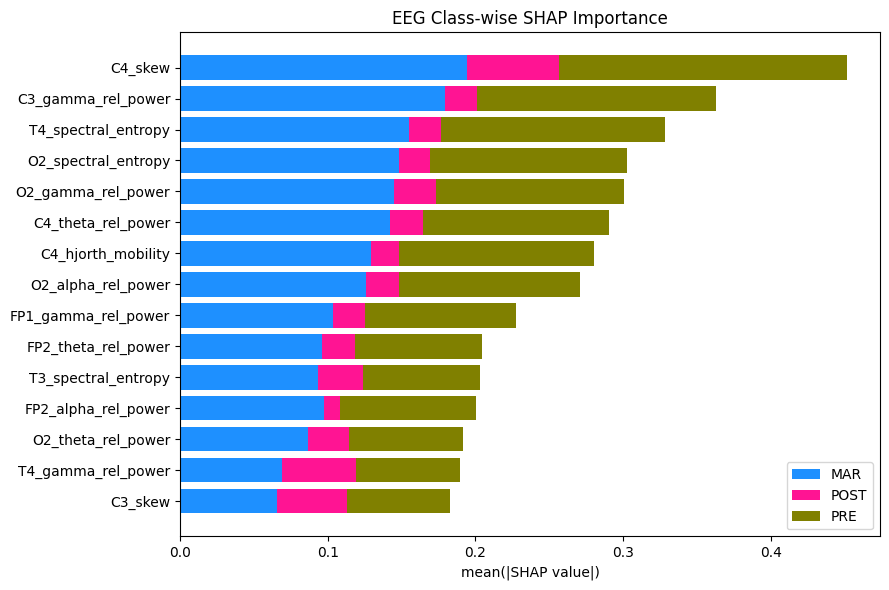

Running ECG SHAP
Saving SHAP plot for: ECG


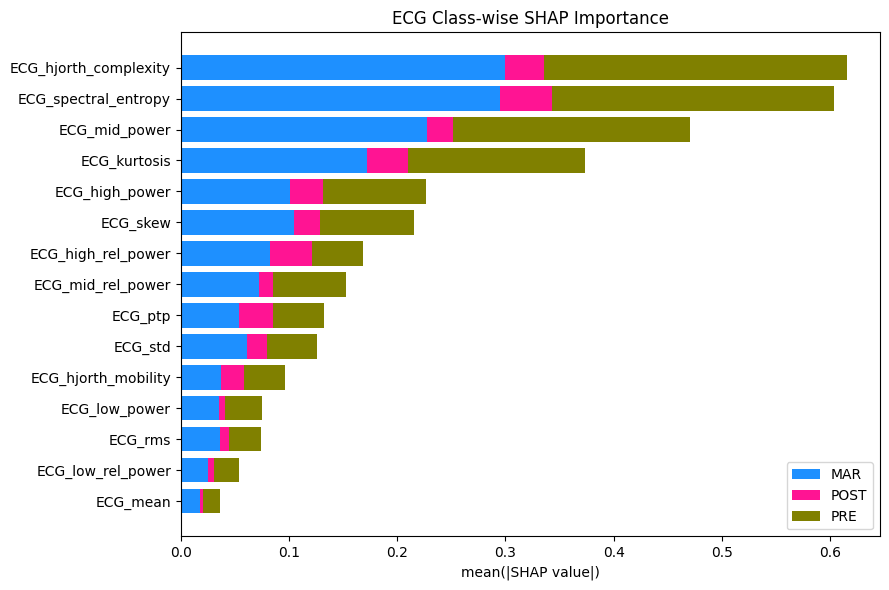

Running EMG SHAP
Saving SHAP plot for: EMG


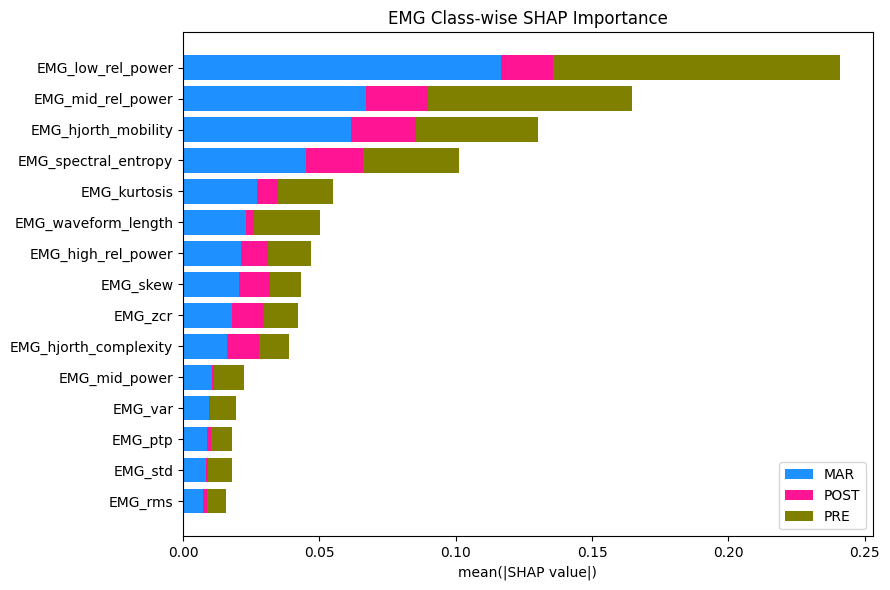

In [54]:
# =========================================================
# CLASS-WISE STACKED SHAP PLOT
# =========================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# FUNCTION
# ---------------------------------------------------------

def stacked_shap_plot(shap_array, feature_names, modality_name):

    classwise = np.abs(shap_array).mean(axis=0)
    total_importance = classwise.sum(axis=1)

    top_idx = np.argsort(total_importance)[-15:]

    top_features = [feature_names[i] for i in top_idx]

    top_vals = classwise[top_idx]

    # -----------------------------------------------------
    # STACKED BAR
    # -----------------------------------------------------

    plt.figure(figsize=(9,6))

    left = np.zeros(len(top_idx))

    colors = ["dodgerblue", "deeppink", "olive"]

    for cls in range(top_vals.shape[1]):

        plt.barh(
            top_features,
            top_vals[:, cls],
            left=left,
            color=colors[cls],
            label=classes[cls]
        )

        left += top_vals[:, cls]

    plt.xlabel("mean(|SHAP value|)")
    plt.title(f"{modality_name} Class-wise SHAP Importance")

    plt.legend()

    plt.tight_layout()
    print(f"Saving SHAP plot for: {modality_name}")

    plt.savefig(
    os.path.join(IMG_DIR,f"{modality_name}_Shap_results.png"),
    dpi=600,
    bbox_inches="tight"
)
    plt.show()

# =========================================================
# EEG
# =========================================================
print("Running EEG SHAP")
stacked_shap_plot(
    shap_values[0],
    eeg_names,
    "EEG"
)

# =========================================================
# ECG
# =========================================================
print("Running ECG SHAP")
stacked_shap_plot(
    shap_values[1],
    ecg_names,
    "ECG"
)

# =========================================================
# EMG
# =========================================================
print("Running EMG SHAP")
stacked_shap_plot(
    shap_values[2],
    emg_names,
    "EMG"
)

Fusion dataset shape : (18681, 198)
Fusion feature shape : (18681, 195)
Fusion classes : ['MAR' 'POST' 'PRE']


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [10:29:42] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Fusion SHAP shape : (30, 195, 3)
Fusion SHAP CSV saved:
/content/drive/MyDrive/Sourcedata/Analysis/SHAP/Fusion_SHAP_Classwise_Importance.csv


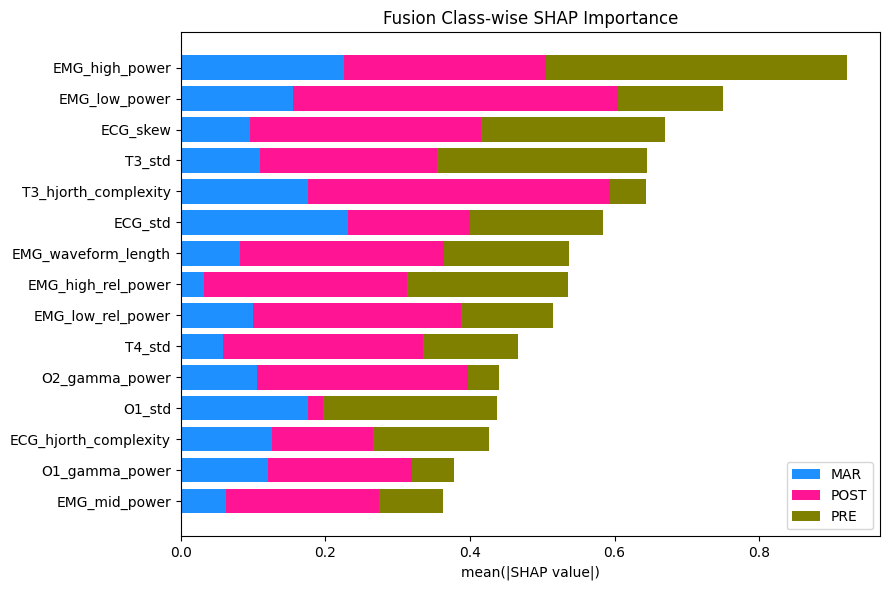

Fusion SHAP plot saved:
/content/drive/MyDrive/Sourcedata/Analysis/Images/Fusion_Shap_results.png


In [55]:
# =========================================================
# FUSION
# =========================================================

import pandas as pd
import numpy as np
import shap
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
fusion_path = "/content/drive/MyDrive/Sourcedata/extracted_data/Fusion_features.csv"

fusion_df = pd.read_csv(fusion_path)

print("Fusion dataset shape :", fusion_df.shape)

y = fusion_df["phase"]

meta_cols = [
    "file_name",
    "window_id",
    "sample_rate",
    "split_mode",
    "subject_id"
]

X = fusion_df.drop(
    columns=[c for c in meta_cols if c in fusion_df.columns] + ["phase"],
    errors="ignore"
)

X = X.select_dtypes(include=np.number)

X = X.fillna(X.median())

print("Fusion feature shape :", X.shape)


le_fusion = LabelEncoder()

y_enc = le_fusion.fit_transform(y)

print("Fusion classes :", le_fusion.classes_)


X_train_fusion, X_test_fusion, y_train_fusion, y_test_fusion = train_test_split(
    X,
    y_enc,
    test_size=0.2,
    stratify=y_enc,
    random_state=42
)

fusion_xgb = XGBClassifier(
    n_estimators=200,
    eval_metric="mlogloss",
    use_label_encoder=False,
    random_state=42
)

fusion_xgb.fit(
    X_train_fusion,
    y_train_fusion
)

fusion_explainer = shap.TreeExplainer(
    fusion_xgb
)

rng = np.random.RandomState(42)

fusion_idx = rng.choice(
    len(X_test_fusion),
    size=min(30, len(X_test_fusion)),
    replace=False
)

fusion_samples = X_test_fusion.iloc[fusion_idx]

fusion_shap_values = fusion_explainer.shap_values(
    fusion_samples
)

if isinstance(fusion_shap_values, list):
    fusion_shap_array = np.stack(
        fusion_shap_values,
        axis=-1
    )

else:

    fusion_shap_array = np.asarray(
        fusion_shap_values
    )

    if fusion_shap_array.ndim == 2:
        fusion_shap_array = fusion_shap_array[:, :, np.newaxis]


print(
    "Fusion SHAP shape :",
    fusion_shap_array.shape
)

fusion_shap_importance = np.abs(
    fusion_shap_array
).mean(axis=0)

fusion_shap_df = pd.DataFrame(
    fusion_shap_importance,
    index=X.columns,
    columns=le_fusion.classes_
)

fusion_shap_df["Total_SHAP"] = fusion_shap_df.sum(axis=1)

fusion_shap_df = fusion_shap_df.sort_values(
    "Total_SHAP",
    ascending=False
)

fusion_shap_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "Fusion_SHAP_Classwise_Importance.csv"
    )
)

print(
    "Fusion SHAP CSV saved:"
)

print(
    os.path.join(
        SHAP_DIR,
        "Fusion_SHAP_Classwise_Importance.csv"
    )
)

top_idx = np.argsort(
    fusion_shap_df["Total_SHAP"].values
)[-15:]

top_features = fusion_shap_df.index[top_idx]

top_vals = fusion_shap_df.loc[
    top_features,
    le_fusion.classes_
].values

plt.figure(figsize=(9, 6))

left = np.zeros(len(top_features))

colors = [
    "dodgerblue",
    "deeppink",
    "olive"
]

for cls in range(top_vals.shape[1]):

    plt.barh(
        top_features,
        top_vals[:, cls],
        left=left,
        color=colors[cls],
        label=le_fusion.classes_[cls]
    )

    left += top_vals[:, cls]


plt.xlabel("mean(|SHAP value|)")
plt.title("Fusion Class-wise SHAP Importance")
plt.legend()

plt.tight_layout()


plt.savefig(
    os.path.join(
        IMG_DIR,
        "Fusion_Shap_results.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print(
    "Fusion SHAP plot saved:"
)

print(
    os.path.join(
        IMG_DIR,
        "Fusion_Shap_results.png"
    )
)

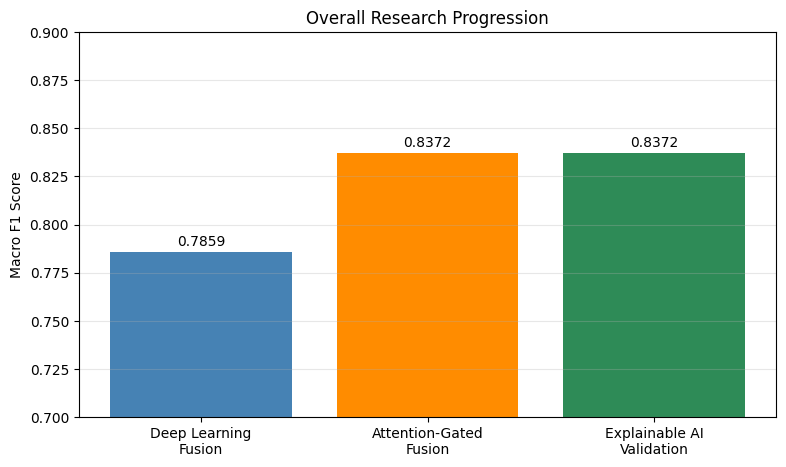

In [47]:
# =========================================================
# FINAL OBJECTIVE COMPARISON
# =========================================================

import matplotlib.pyplot as plt

objectives = [

    "Deep Learning\nFusion",

    "Attention-Gated\nFusion",

    "Explainable AI\nValidation"
]

f1_scores = [

    0.7859,

    0.8372,

    0.8372
]

colors = [

    "steelblue",

    "darkorange",

    "seagreen"
]

plt.figure(figsize=(9,5))

bars = plt.bar(
    objectives,
    f1_scores,
    color=colors
)

for i, (b, v) in enumerate(zip(bars, f1_scores)):

    txt = f"{v:.4f}"

    if i == 2:
        txt += ""

    plt.text(
        b.get_x() + b.get_width()/2,
        v + 0.003,
        txt,
        ha="center",
        fontsize=10
    )

plt.ylabel("Macro F1 Score")

plt.title("Overall Research Progression")

plt.ylim(0.70, 0.90)

plt.grid(axis="y", alpha=0.3)
plt.savefig(
    os.path.join(IMG_DIR, "final comparison.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [58]:
# =========================================================
# STATISTICAL VALIDATION
# =========================================================

import numpy as np
from scipy.stats import ttest_rel, wilcoxon
import scipy.stats as st

# ---------------------------------------------------------
# FOLD RESULTS
# ---------------------------------------------------------

obj2_f1 = np.array([
    0.78278,
    0.79528,
    0.76928,
    0.79068,
    0.79148
])

obj3_f1 = np.array([
    0.84476,
    0.84066,
    0.82886,
    0.84766,
    0.82406
])
# =========================================================
# PAIRED T-TEST
# =========================================================

t_stat, p_val = ttest_rel(obj3_f1, obj2_f1)

# =========================================================
# WILCOXON
# =========================================================

w_stat, w_p = wilcoxon(obj3_f1, obj2_f1)

# =========================================================
# COHEN D
# =========================================================

diff = obj3_f1 - obj2_f1

cohen_d = diff.mean() / diff.std(ddof=1)

# =========================================================
# 95% CONFIDENCE INTERVAL
# =========================================================

ci = st.t.interval(
    0.95,
    len(diff)-1,
    loc=np.mean(diff),
    scale=st.sem(diff)
)

# =========================================================
# PRINT RESULTS
# =========================================================

print("========== STATISTICAL VALIDATION ==========\n")

print("Paired t-test p-value :", round(p_val,6))

print("Wilcoxon p-value      :", round(w_p,6))

print("Cohen's d             :", round(cohen_d,4))

print("95% Confidence Interval :", ci)

========== STATISTICAL VALIDATION ==========

Paired t-test p-value : 0.000725
Wilcoxon p-value      : 0.0625
Cohen's d             : 4.1873
95% Confidence Interval : (np.float64(0.03608812103065924), np.float64(0.06651187896934074))


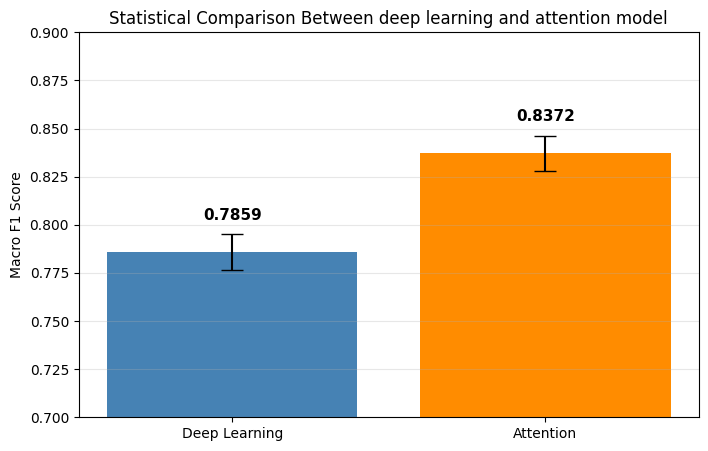

In [49]:
# 28=========================================================
# STATISTICAL PERFORMANCE COMPARISON
# =========================================================

import matplotlib.pyplot as plt
import numpy as np

means = [

    np.mean(obj2_f1),

    np.mean(obj3_f1)
]

stds = [

    np.std(obj2_f1),

    np.std(obj3_f1)
]

labels = [

    "Deep Learning",

    "Attention"
]

plt.figure(figsize=(8,5))

bars = plt.bar(
    labels,
    means,
    yerr=stds,
    capsize=8,
    color=["steelblue", "darkorange"]
)

for i, (b, v) in enumerate(zip(bars, means)):

    plt.text(
        b.get_x() + b.get_width()/2,
        v + stds[i] + 0.006,
        f"{v:.4f}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"

    )

plt.ylabel("Macro F1 Score")

plt.title("Statistical Comparison Between deep learning and attention model")

plt.ylim(0.70, 0.90)

plt.grid(axis="y", alpha=0.3)

plt.savefig(
    os.path.join(IMG_DIR, "comparison_only_btw_obj2&3.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()